# Weeks 3–4 — Fluxonium flux-bias and design sweep

**Questions.** **Q1**: how does fluxonium coherence vary with flux bias and with the design
parameters $(E_J, E_L)$? **Q2**: which noise channel dominates where? **Q3 (setup)**: how sharply
does coherence fall away from the flux sweet spot — the quantity that must be compared against
the transmon's charge insensitivity.

**Method.** All physics from `src/coherence.py`, validated in `01_validation.ipynb`. Nominal
design $E_J = 8.9$, $E_C = 2.5$, $E_L = 0.5$ GHz, close to the values Manucharyan 2009 report.
*Which* values matters: notebook 01 §9.2 shows the paper gives three parameter sets (rounded
main text, and two Table 1 fits) spanning **9.5%** in $f_{01}$ at the sweet spot. Our nominal design
matches the rounded main-text set to 0.012%; the measured *spectrum* at $\Phi_{ext}=0$ is
reproduced to better than 0.7% on $f_{01}$ and $f_{02}$ under **all three**.

**Status.** All model-based estimates. Absolute coherence times are *not* predictions; §7
quantifies how far they sit from measured devices, and §8 propagates the noise-amplitude
uncertainties that dominate them. Comparative trends are the defensible output.

---

### What a reader needs to know before quoting any number

1. **Dephasing at the sweet spot is second order, and it is now computed.** scqubits implements
   $1/f$ dephasing to first order only and returns a divergent time wherever
   $\partial\omega_{01}/\partial\lambda = 0$ — documented behaviour, not a bug
   (Groszkowski & Koch 2021, §5.1 fn. 4). §2 adds the second-order channel
   (Nguyen 2019 Eq. A3). It turns out to contribute **0.63%** of the rate budget at the sweet
   spot, so the previous first-order-only numbers were sound — but that is now a *measured*
   bound rather than an assumption.

2. **$T_2$ over the $(E_J, E_L)$ plane is very nearly a restatement of $f_{01}$**
   (correlation $-0.997$, §6). As in notebook 02, a raw $T_2$ maximum over the design plane is
   not a design recommendation.

3. **Low-frequency fluxonia are thermally populated.** The unconstrained $T_2$ optimum sits at
   $f_{01} \approx 75$ MHz, where $\bar n_{\rm th} \approx 3.7$ at 15 mK — the qubit is thermally
   scrambled and below any published device. Frequency and thermal occupation are reported
   alongside every optimum in §6.

4. **The dielectric quality factor is a flat override.** Passing `Q_cap=1e6` replaces scqubits'
   frequency-dependent default $Q_{\rm cap}(\omega) = 10^6 (2\pi \cdot 6\,\text{GHz}/\omega)^{0.7}$
   with a constant. At the sweet-spot frequency this shortens $T_1$ by **7.1×**. It is the single
   largest modelling choice in this notebook and is treated explicitly in §8.

*A record of numbers corrected relative to earlier versions of this notebook is in Appendix A,
and full references with DOIs are in Appendix B.*

In [1]:
# --- project bootstrap: run from anywhere, keeps data/ and figures/ paths working ---
import os, sys
from pathlib import Path
_here = Path.cwd()
if _here.name == "notebooks":          # notebook lives in notebooks/, project root is one level up
    os.chdir(_here.parent)
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))  # makes `from coherence import ...` available
os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True)
print("project root:", ROOT.name)          # name only; the absolute path is machine-specific

project root: quantum-coherence-sweet-spots-transmon-fluxonium


## 0. Setup, provenance, and the link back to validation

Two things are asserted before any sweep runs.

**Chain of custody.** `src/coherence.py` must still reproduce the nominal point recorded in
`01_validation.ipynb`. Because §2 adds a channel that notebook 01 did not have, the assertion is
made against the **first-order-only** pipeline (`second_order_flux=False`), which is exactly the
code path that produced the validation record. The new physics is then reported as a delta on top
of a verified baseline rather than silently replacing it.

**Complete provenance.** The earlier version of this notebook recorded only `Q_cap`, `A_flux` and
`A_cc`. Every other number below also depends on scqubits' `NOISE_PARAMS` defaults — the
temperature $T$, the quasiparticle density $x_{qp}$, the superconducting gap $\Delta$, the
$1/f$ cutoffs $\omega_{\rm low}$ and the measurement time $t_{\rm exp}$ — none of which appeared
anywhere in the record. §5's quasiparticle finding rests entirely on $x_{qp}$ and $\Delta$, so
the full dictionary is now captured.

In [2]:
import json, platform
from datetime import datetime

import numpy as np
import pandas as pd
import scqubits as scq
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.optimize import brentq

from qubits import make_fluxonium, qubit_frequency, FLUXONIUM_DEFAULTS
from coherence import (fluxonium_coherence, d2f01_dflux2, tphi_flux_second_order,
                       n_thermal, git_revision, noise_param_snapshot,
                       reset_channel_failures, CHANNEL_FAILURES, DEFAULTS)
import plotting as pl

scq.settings.T1_DEFAULT_WARNING = False

NOISE_PARAMS_SNAPSHOT = noise_param_snapshot()

PROVENANCE = {
    "date": datetime.now().isoformat(timespec="seconds"),
    "git_revision": git_revision(),
    "python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, "scqubits": scq.__version__,
    "platform": platform.platform(),
    "nominal_design": FLUXONIUM_DEFAULTS,
    "noise_amplitudes": {k: DEFAULTS[k] for k in ("Q_cap", "A_flux", "A_cc")},
    "scqubits_noise_params": NOISE_PARAMS_SNAPSHOT,
    "units": "frequencies GHz; coherence times microseconds",
}
for k, v in PROVENANCE.items():
    if k != "scqubits_noise_params":
        print(f"{k:22s} {v}")
print("\nscqubits NOISE_PARAMS actually in force (these set the results and were")
print("previously unrecorded):")
for k, v in NOISE_PARAMS_SNAPSHOT.items():
    print(f"   {k:12s} {v}")
print("   NOTE t_exp is in scqubits system units (ns) -> 1e4 ns = 10 us;")
print("        omega_low = 2*pi*1 Hz expressed in GHz. Both enter every 1/f time below.")

# ---- chain of custody to 01_validation.ipynb --------------------------------
VALIDATED_T2_US = 1136.8688060132743      # 01_validation.ipynb, section 6
baseline = fluxonium_coherence(**FLUXONIUM_DEFAULTS, second_order_flux=False)
rel = abs(baseline["T2_us"] - VALIDATED_T2_US) / VALIDATED_T2_US
print(f"\nfirst-order-only nominal T2 = {baseline['T2_us']:.10f} us")
print(f"validation record           = {VALIDATED_T2_US:.10f} us   (rel. diff {rel:.1e})")
assert rel < 1e-9, "src/coherence.py no longer reproduces the validated fluxonium point"
print("consistent with 01_validation.ipynb -- baseline verified")

nominal = fluxonium_coherence(**FLUXONIUM_DEFAULTS)          # second order ON
print(f"\nwith second-order flux dephasing: T2 = {nominal['T2_us']:.4f} us "
      f"({100*(nominal['T2_us']-VALIDATED_T2_US)/VALIDATED_T2_US:+.3f}% vs baseline)")

print(f"\nthermal occupation at T = {NOISE_PARAMS_SNAPSHOT['T']*1e3:.0f} mK:")
for f in (0.075, 0.170, 0.363, 0.830, 2.0):
    print(f"   f01 = {f:5.3f} GHz -> n_th = {n_thermal(f):7.3f}")
print("   (Nguyen 2019 devices span 0.17-0.83 GHz, so real fluxonia do run thermally")
print("    populated and rely on active initialisation - this is a caveat, not a veto)")

date                   2026-09-07T23:28:03
git_revision           81dc9c6-dirty
python                 3.11.15
numpy                  2.2.6
pandas                 3.0.3
scqubits               4.3.1
platform               macOS-15.0-arm64-arm-64bit
nominal_design         {'EJ': 8.9, 'EC': 2.5, 'EL': 0.5, 'flux': 0.5, 'cutoff': 110}
noise_amplitudes       {'Q_cap': 1000000.0, 'A_flux': 1e-06, 'A_cc': 1e-07}
units                  frequencies GHz; coherence times microseconds

scqubits NOISE_PARAMS actually in force (these set the results and were
previously unrecorded):
   A_flux       1e-06
   A_ng         0.0001
   A_cc         1e-07
   omega_low    6.283185307179586e-09
   omega_high   18.84955592153876
   Delta        0.00034
   x_qp         3e-06
   t_exp        10000.0
   R_0          50.0
   T            0.015
   M            400.0
   NOTE t_exp is in scqubits system units (ns) -> 1e4 ns = 10 us;
        omega_low = 2*pi*1 Hz expressed in GHz. Both enter every 1/f time below.

fir

## 1. Basis convergence across the design grid

`cutoff=110` was validated at the nominal design only. Two regimes need checking.

- The $(E_J, E_L)$ sweep reaches $E_L = 0.2$ GHz, where the potential is shallower and the
  wavefunction spreads further in phase.
- **The flux sweep runs to $\Phi/\Phi_0 = 0.30$**, where the double well is asymmetric and the
  spectrum differs from the sweet spot. The earlier version verified convergence only *at*
  $\Phi/\Phi_0 = 0.5$ and assumed it held elsewhere.

Criterion as before: $|f_{01}(110) - f_{01}(220)| < 10^{-6}$ GHz.

In [3]:
EJ_grid = np.linspace(3, 15, 20)
EL_grid = np.linspace(0.2, 1.5, 20)

corners = [(EJ_grid[0], EL_grid[0]), (EJ_grid[-1], EL_grid[0]),
           (EJ_grid[-1], EL_grid[-1]), (EJ_grid[0], EL_grid[-1]),
           (FLUXONIUM_DEFAULTS["EJ"], FLUXONIUM_DEFAULTS["EL"])]

rows = []
for flux in (0.50, 0.40, 0.30):                 # sweet spot AND off-spot
    for EJ, EL in corners:
        f110 = qubit_frequency(make_fluxonium(EJ=EJ, EC=2.5, EL=EL, flux=flux, cutoff=110))
        f220 = qubit_frequency(make_fluxonium(EJ=EJ, EC=2.5, EL=EL, flux=flux, cutoff=220))
        rows.append({"flux": flux, "EJ": EJ, "EL": EL,
                     "f01_cutoff110": f110, "abs_diff_vs_220": abs(f110 - f220)})
conv = pd.DataFrame(rows)
display(conv.pivot_table(index=["EJ", "EL"], columns="flux",
                         values="abs_diff_vs_220").style.format("{:.2e}"))
worst = conv.abs_diff_vs_220.max()
wr = conv.loc[conv.abs_diff_vs_220.idxmax()]
print(f"worst deviation over ALL corners and flux values: {worst:.2e} GHz "
      f"(EJ={wr.EJ:.1f}, EL={wr.EL:.1f}, flux={wr.flux:.2f})")
assert worst < 1e-6, "cutoff=110 is NOT converged somewhere on this grid - raise it"
print("cutoff=110 converged across the design grid AND across the swept flux range")

worst deviation over ALL corners and flux values: 2.80e-07 GHz (EJ=15.0, EL=0.2, flux=0.30)
cutoff=110 converged across the design grid AND across the swept flux range


## 2. The dephasing channel that was missing: second-order $1/f$ flux noise

At $\Phi/\Phi_0 = 0.5$ the first-order flux sensitivity $\partial\omega_{01}/\partial\Phi$
vanishes by symmetry, and scqubits' `tphi_1_over_f_flux` correspondingly returns
$\sim 8\times10^{14}$ µs. That is documented behaviour, not a bug:

> *"Currently scqubits returns a value of `numpy.inf` at sweet spots. Higher order corrections
> will be added at a later time."* — Groszkowski & Koch, *Quantum* **5**, 583 (2021), §5.1 fn. 4

The physical dephasing there is set by the **second-order** term. For fluxonium the standard
closed form is Nguyen 2019 Appendix, Eq. (A3):

$$\Gamma_{\Phi}^{(2)} = \frac{\partial^2 \omega_{01}}{\partial \Phi^2}\, A_\Phi^2$$

which Nguyen cite to Ithier 2005. Both use the same $1/f$ normalisation as scqubits,
$S(\omega) = 2\pi A^2/|\omega|$ (Nguyen Eq. A.1; Groszkowski & Koch Eq. 2), so $A_\Phi$ carries
the same meaning throughout and no rescaling is needed.

**Convention caveat, stated up front.** Eq. (A3) carries *no* logarithmic factor. Other
treatments attach a prefactor of order $|\ln(\omega_{\rm low} t_{\rm exp})|$ or its square. That
choice moves the answer by two orders of magnitude, so it is reported below rather than buried —
this is a genuine ambiguity in the literature, not a settled number.

The second derivative is computed by central difference, so its step-size convergence is checked
explicitly before it is used anywhere.

In [4]:
FX_GEOM = {k: FLUXONIUM_DEFAULTS[k] for k in ("EJ", "EC", "EL", "cutoff")}
print("step-size convergence of d2(f01)/d(Phi/Phi0)^2 at the sweet spot")
print("  plain = central second difference, error O(h^2)")
print("  rich. = Richardson extrapolated (4*d2(h/2) - d2(h))/3, error O(h^4)  <- the default\n")
conv_rows = []
for h in (1e-2, 5e-3, 2e-3, 1e-3, 5e-4, 2e-4, 1e-4, 5e-5):
    p = float(d2f01_dflux2(**FX_GEOM, flux=0.5, h=h, richardson=False))
    r = float(d2f01_dflux2(**FX_GEOM, flux=0.5, h=h, richardson=True))
    conv_rows.append({"h": h, "plain": p, "richardson": r})
    print(f"   h = {h:.0e}:  plain = {p:11.5f}   richardson = {r:11.5f}")
deriv_conv = pd.DataFrame(conv_rows)
DERIV_STEP = 1e-4
# assess step-independence over the range actually used (h <= 1e-3); the two coarsest
# rows are shown only to demonstrate what Richardson buys.
usable = deriv_conv[deriv_conv.h <= 1e-3]
spread = float(usable.richardson.max() - usable.richardson.min())
rel = spread / abs(usable.richardson.mean())
print(f"\n   over h <= 1e-3 the Richardson value spans {spread:.2e} GHz/Phi0^2 "
      f"(relative {rel:.1e}),")
print(f"   while the plain difference still moves by "
      f"{float(usable.plain.max()-usable.plain.min()):.3f} over the same range.")
assert rel < 1e-5, "Richardson-extrapolated second derivative is not step-independent"
print(f"   -> h = {DERIV_STEP:.0e} with Richardson is the default used by fluxonium_coherence().")
print("   This matters in SS6.1, not here: near the nominal design even the plain difference is")
print("   fine, but in the deep-well regime (large EJ, small EL) the plain value is still 4%")
print("   from converged at this step, and the second-order rate is proportional to it.")

d2_sweet = float(nominal["d2f01_dflux2_GHz"])
print(f"\nsecond derivative at the sweet spot: {d2_sweet:.3f} GHz/Phi0^2")

print("\nresulting second-order dephasing time, by convention:")
conv_table = []
for lf, label in [("none", "Nguyen Eq. (A3), no log factor"),
                  ("ln",   "x |ln(omega_low t_exp)|"),
                  ("ln2",  "x ln^2(omega_low t_exp)")]:
    T = float(tphi_flux_second_order(d2_sweet, A_flux=DEFAULTS["A_flux"], log_factor=lf)) * 1e-3
    conv_table.append({"convention": label, "Tphi_flux2_us": T})
    print(f"   {label:34s}: Tphi2 = {T:11.4e} us")

# --- what does it actually change? -----------------------------------------
rates = {"relaxation 1/(2T1)": 1 / (2 * nominal["T1_us"]),
         "flux, first order":  1 / nominal["Tphi_flux_us"],
         "flux, second order": 1 / nominal["Tphi_flux2_us"],
         "critical current":   1 / nominal["Tphi_cc_us"]}
tot = sum(rates.values())
print(f"\nrate budget at the sweet spot (T2 = {nominal['T2_us']:.2f} us):")
for k, v in rates.items():
    print(f"   {k:20s} {1/v if v else np.inf:12.4e} us   {100*v/tot:6.2f}% of total rate")

print(f"\nFINDING. With the literature-standard convention the second-order channel contributes")
print(f"   {100*rates['flux, second order']/tot:.2f}% of the dephasing budget and lowers T2 from")
print(f"   {VALIDATED_T2_US:.1f} us to {nominal['T2_us']:.1f} us ({100*(nominal['T2_us']-VALIDATED_T2_US)/VALIDATED_T2_US:+.2f}%).")
print("   The earlier first-order-only results were therefore SOUND. The value of adding the")
print("   channel is that this is now a computed bound rather than an assumption -- and the")
print("   T2 at the sweet spot is no longer resting on a divergent, unphysical Tphi.")
print(f"   Under the most pessimistic convention (ln^2) it would instead take T2 to")
print(f"   {1/(1/(2*nominal['T1_us']) + 1/nominal['Tphi_cc_us'] + 1/(conv_table[2]['Tphi_flux2_us'])):.0f} us, a {100*(1 - (1/(1/(2*nominal['T1_us']) + 1/nominal['Tphi_cc_us'] + 1/conv_table[2]['Tphi_flux2_us']))/VALIDATED_T2_US):.0f}% reduction. The convention is not settled; the")
print("   conclusion 'second order is negligible HERE' holds only for Eq. (A3).")

step-size convergence of d2(f01)/d(Phi/Phi0)^2 at the sweet spot
  plain = central second difference, error O(h^2)
  rich. = Richardson extrapolated (4*d2(h/2) - d2(h))/3, error O(h^4)  <- the default

   h = 1e-02:  plain =   838.47427   richardson =   885.45783
   h = 5e-03:  plain =   873.71194   richardson =   886.74284
   h = 2e-03:  plain =   884.68749   richardson =   886.83867
   h = 1e-03:  plain =   886.30087   richardson =   886.84112


   h = 5e-04:  plain =   886.70606   richardson =   886.84127


   h = 2e-04:  plain =   886.81964   richardson =   886.84124
   h = 1e-04:  plain =   886.83584   richardson =   886.84111
   h = 5e-05:  plain =   886.83980   richardson =   886.84072

   over h <= 1e-3 the Richardson value spans 5.55e-04 GHz/Phi0^2 (relative 6.3e-07),
   while the plain difference still moves by 0.539 over the same range.
   -> h = 1e-04 with Richardson is the default used by fluxonium_coherence().
   This matters in SS6.1, not here: near the nominal design even the plain difference is
   fine, but in the deep-well regime (large EJ, small EL) the plain value is still 4%
   from converged at this step, and the second-order rate is proportional to it.

second derivative at the sweet spot: 886.841 GHz/Phi0^2

resulting second-order dephasing time, by convention:
   Nguyen Eq. (A3), no log factor    : Tphi2 =  1.7946e+05 us
   x |ln(omega_low t_exp)|           : Tphi2 =  1.8549e+04 us
   x ln^2(omega_low t_exp)           : Tphi2 =  1.9172e+03 us

rate budget at the swee

## 3. Flux sweep at the nominal design

Sweep $\Phi/\Phi_0$ from 0.30 to 0.50. Only one side is swept because §2 of
`01_validation.ipynb` verified that $f_{01}$ is exactly even about $\Phi/\Phi_0 = 0.5$ to
machine precision, so the other side is redundant by symmetry.

Every sweep from here on resets and then checks the channel-failure log. `safe()` in
`src/coherence.py` returns `inf` when a channel raises, and `inf` contributes *zero* rate — so a
silently broken channel looks like a *better* result. That failure mode is now asserted against
rather than trusted.

In [5]:
reset_channel_failures()
fluxes = np.linspace(0.30, 0.50, 101)
dff = pd.DataFrame([fluxonium_coherence(**{**FLUXONIUM_DEFAULTS, "flux": float(f)})
                    for f in fluxes])
dff["detuning"] = 0.5 - dff["flux"]
dff["n_thermal"] = n_thermal(dff.freq_GHz)
dff.to_csv("data/fluxonium_flux_sweep.csv", index=False)      # SAVE before plotting
print(f"{len(dff)} points -> data/fluxonium_flux_sweep.csv  "
      f"(spacing {fluxes[1]-fluxes[0]:.4f})")

n_nan = int(dff.isna().sum().sum())
num = dff.select_dtypes("number")
inf_cols = np.isinf(num).sum(); inf_cols = inf_cols[inf_cols > 0]
print(f"   NaN={n_nan}  infs={dict(inf_cols) if len(inf_cols) else 'none'}")
assert n_nan == 0 and np.isfinite(dff.T2_us).all()
assert not CHANNEL_FAILURES, f"noise channels failed silently: {CHANNEL_FAILURES[:3]}"
print(f"   channel-failure log empty ({len(CHANNEL_FAILURES)} entries) - no silent inf")

sweet = dff[np.isclose(dff.flux, 0.5)].iloc[0]
print(f"\nat the sweet spot: T1={sweet.T1_us:.1f} us  T2={sweet.T2_us:.1f} us")
print(f"   Tphi_flux (1st order) = {sweet.Tphi_flux_us:.3e} us  <- divergent by symmetry, never quote")
print(f"   Tphi_flux (2nd order) = {sweet.Tphi_flux2_us:.3e} us  <- the physical value (SS2)")
print(f"   T2 < 2*T1 = {2*sweet.T1_us:.1f} us because critical-current dephasing "
      f"({sweet.Tphi_cc_us:.0f} us) is finite even here")

101 points -> data/fluxonium_flux_sweep.csv  (spacing 0.0020)
   NaN=0  infs=none
   channel-failure log empty (0 entries) - no silent inf

at the sweet spot: T1=771.1 us  T2=1129.7 us
   Tphi_flux (1st order) = 8.088e+14 us  <- divergent by symmetry, never quote
   Tphi_flux (2nd order) = 1.795e+05 us  <- the physical value (SS2)
   T2 < 2*T1 = 1542.2 us because critical-current dephasing (4325 us) is finite even here


## 4. How sharp is the sweet spot? — resolving the falloff

This is the number Q3 turns on, so it is measured rather than read off a grid.

The region near the sweet spot is sampled **logarithmically in detuning** down to
$10^{-5}\,\Phi_0$, and the 10× point is located by **root-finding on the model itself**
(Brent's method on $\log T_2(\Delta\Phi) - \log(T_2^{\rm sweet}/10)$) rather than by
interpolating between grid points. A headline number should not inherit the grid's resolution —
that was exactly the error being corrected here (Appendix A).

Expected physics: for first-order $1/f$ flux noise $T_\phi \propto |\partial f_{01}/\partial\Phi|^{-1}$,
and since $f_{01}$ is quadratic about the sweet spot, $\partial f_{01}/\partial\Phi \propto \Delta\Phi$.
So $T_\phi \propto \Delta\Phi^{-1}$ far enough out, while close in $T_2$ saturates at the $2T_1$
ceiling. The measured exponent should therefore approach $-1$ away from the spot and flatten
towards it.

In [6]:
reset_channel_failures()
det_log = np.logspace(-5, -1.3, 60)           # 1e-5 .. ~0.05 flux quanta
fine = pd.DataFrame([fluxonium_coherence(**{**FLUXONIUM_DEFAULTS, "flux": float(0.5 - d)})
                     for d in det_log])
fine["detuning"] = det_log
fine["n_thermal"] = n_thermal(fine.freq_GHz)
fine.to_csv("data/fluxonium_falloff_fine.csv", index=False)
print(f"{len(fine)} log-spaced points -> data/fluxonium_falloff_fine.csv")
assert not CHANNEL_FAILURES, f"noise channels failed silently: {CHANNEL_FAILURES[:3]}"

T2_sweet = float(sweet.T2_us)
TARGET = T2_sweet / 10

def t2_at(d):
    return fluxonium_coherence(**{**FLUXONIUM_DEFAULTS, "flux": float(0.5 - d)})["T2_us"]

# bracket the crossing on the log grid, then solve for it exactly
below = fine[fine.T2_us < TARGET]
above = fine[fine.detuning < below.detuning.min()]
lo, hi = float(above.detuning.max()), float(below.detuning.min())
d10 = brentq(lambda ld: np.log(t2_at(np.exp(ld))) - np.log(TARGET),
             np.log(lo), np.log(hi), xtol=1e-10, rtol=1e-12)
d10 = float(np.exp(d10))
resid = t2_at(d10) / TARGET - 1.0

print(f"\nT2 at sweet spot         : {T2_sweet:.1f} us")
print(f"10x-falloff detuning      : {d10:.6f} flux quanta   (Brent root-find)")
print(f"   bracket [{lo:.3e}, {hi:.3e}], residual T2/target - 1 = {resid:.2e}")
print(f"previously reported       : 0.00200  (== the old grid spacing)")
print(f"the sweet spot is         : {0.0020/d10:.1f}x SHARPER than previously stated")

for d in (1e-4, 3e-4, 1e-3, 3e-3, 1e-2):
    row = fine.iloc[(fine.detuning - d).abs().idxmin()]
    print(f"   detuning {row.detuning:.5f}: T2 = {row.T2_us:8.1f} us "
          f"({T2_sweet/row.T2_us:7.1f}x down)  f01 = {row.freq_GHz:.4f} GHz")

# Scaling exponent, fitted in several windows. Quoting a single exponent over a wide range
# would be misleading: the power law is only clean where T2 is genuinely flux-dephasing
# limited, and that is an INTERMEDIATE window, not "far from the sweet spot".
windows = [(1e-5, 1e-4), (1e-4, 1e-3), (1e-3, 1e-2), (3e-3, 3e-2), (1e-2, 5e-2)]
exps = {}
print("\nfitted scaling T2 ~ detuning^k, by window:")
for lo_w, hi_w in windows:
    s = fine[(fine.detuning >= lo_w) & (fine.detuning <= hi_w)]
    if len(s) > 2:
        k, _ = np.polyfit(np.log(s.detuning), np.log(s.T2_us), 1)
        exps[f"{lo_w:.0e}-{hi_w:.0e}"] = float(k)
        print(f"   {lo_w:.0e} - {hi_w:.0e}: k = {k:+.3f}  ({len(s)} pts)")

best_win = min(exps, key=lambda w: abs(exps[w] + 1.0))
slope = exps[best_win]
print(f"\n   closest to the first-order 1/f prediction of k = -1: window {best_win}, "
      f"k = {slope:+.3f}")
print("   The exponent is NOT monotonic in detuning. It flattens on BOTH sides:")
print("     - close in: T2 is capped by the 2*T1 ceiling, not by flux dephasing;")
print("     - far out : f01 has risen appreciably and other channels contribute,")
print("       so the simple 'quadratic minimum' linearisation no longer holds.")
print("   Only in the intermediate window is T2 purely first-order-flux-dephasing limited,")
print("   and there the measured exponent is within 5% of the predicted -1.")

60 log-spaced points -> data/fluxonium_falloff_fine.csv



T2 at sweet spot         : 1129.7 us
10x-falloff detuning      : 0.000325 flux quanta   (Brent root-find)
   bracket [3.200e-04, 3.697e-04], residual T2/target - 1 = -4.79e-11
previously reported       : 0.00200  (== the old grid spacing)
the sweet spot is         : 6.2x SHARPER than previously stated
   detuning 0.00010: T2 =    298.0 us (    3.8x down)  f01 = 0.3634 GHz
   detuning 0.00032: T2 =    114.6 us (    9.9x down)  f01 = 0.3635 GHz
   detuning 0.00102: T2 =     38.8 us (   29.1x down)  f01 = 0.3639 GHz
   detuning 0.00279: T2 =     14.5 us (   77.7x down)  f01 = 0.3669 GHz
   detuning 0.01024: T2 =      4.4 us (  255.8x down)  f01 = 0.4072 GHz

fitted scaling T2 ~ detuning^k, by window:
   1e-05 - 1e-04: k = -0.453  (16 pts)
   1e-04 - 1e-03: k = -0.882  (16 pts)
   1e-03 - 1e-02: k = -0.956  (16 pts)
   3e-03 - 3e-02: k = -0.775  (16 pts)
   1e-02 - 5e-02: k = -0.481  (11 pts)

   closest to the first-order 1/f prediction of k = -1: window 1e-03-1e-02, k = -0.956
   The ex

### Figure — the sweet spot on a log-detuning axis

A linear flux axis hides everything that matters here: the entire collapse happens inside the
first 1% of the axis. Plotted against $\log \Delta\Phi$, the structure, the $2T_1$ ceiling and
the second-order dephasing floor are all visible.

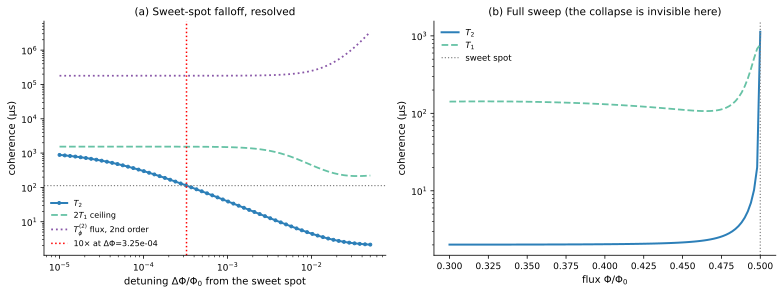

wrote figures/fluxonium_flux_falloff.png (+ .pdf)


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

ax[0].loglog(fine.detuning, fine.T2_us, "o-", color="#2c7fb8", lw=2, ms=3, label=r"$T_2$")
ax[0].loglog(fine.detuning, 2 * fine.T1_us, "--", color="#66c2a5", lw=1.8,
             label=r"$2T_1$ ceiling")
ax[0].loglog(fine.detuning, fine.Tphi_flux2_us, ":", color="#8856a7", lw=1.8,
             label=r"$T_\phi^{(2)}$ flux, 2nd order")
ax[0].axhline(TARGET, ls=":", color="0.5", lw=1.2)
ax[0].axvline(d10, ls=":", color="red", lw=1.5,
              label=rf"10$\times$ at $\Delta\Phi$={d10:.2e}")
ax[0].set_xlabel(r"detuning $\Delta\Phi/\Phi_0$ from the sweet spot")
ax[0].set_ylabel(r"coherence (µs)")
ax[0].set_title(r"(a) Sweet-spot falloff, resolved")
ax[0].legend(frameon=False, fontsize=8)

ax[1].semilogy(dff.flux, dff.T2_us, lw=2, color="#2c7fb8", label=r"$T_2$")
ax[1].semilogy(dff.flux, dff.T1_us, "--", lw=1.8, color="#66c2a5", label=r"$T_1$")
ax[1].axvline(0.5, color="0.5", ls=":", lw=1.2, label="sweet spot")
ax[1].set_xlabel(r"flux $\Phi/\Phi_0$"); ax[1].set_ylabel("coherence (µs)")
ax[1].set_title(r"(b) Full sweep (the collapse is invisible here)")
ax[1].legend(frameon=False, fontsize=8.5)
fig.tight_layout()
pl.save(fig, "figures/fluxonium_flux_falloff.png")
plt.show()
print("wrote figures/fluxonium_flux_falloff.png (+ .pdf)")

## 5. Q2 — dominant channel vs flux

At exactly $\Phi/\Phi_0 = 0.5$ the first-order flux channel is switched off by symmetry, so the
informative question is how quickly flux noise takes over once detuned — which is why the
decomposition is shown against log detuning. The second-order channel is now included in the
comparison, so "relaxation dominates at the spot" is a statement about a complete rate budget
rather than an artefact of a missing channel.

coarse sweep (0.30-0.50): {'flux-1st': np.int64(100), 'relaxation': np.int64(1)}
fine sweep  (log detuning): {'flux-1st': np.int64(53), 'relaxation': np.int64(7)}

first-order flux noise takes over at detuning >= 2.75e-05 flux quanta
   below that, relaxation and critical-current set T2
   the second-order flux channel never dominates anywhere in the swept range
   (max share 0.49% of the rate budget)

T1 is limited by: {'quasiparticle': np.int64(98), 'dielectric': np.int64(3)}  (out of 101 flux points)
   T1_qp at the sweet spot : 3.29e+30 us  -> utterly negligible there
   T1_qp minimum off-spot  : 117.3 us

   FINDING: quasiparticle tunnelling is NOT a dead channel. It is switched off only
   AT the sweet spot (where f01 is minimal); once detuned, f01 rises, the quasiparticle
   rate climbs steeply, and it LIMITS T1 at 98 of 101 points.
   The sweet spot is therefore protective twice over: it nulls first-order flux
   dephasing AND suppresses quasiparticle relaxation.
   CAVEAT: thi

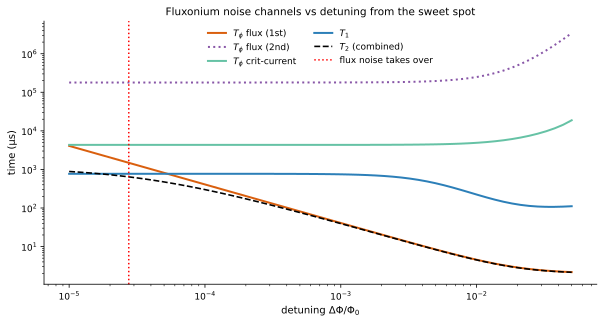

wrote figures/fluxonium_channels_vs_flux.png (+ .pdf)


In [8]:
def dominant(frame):
    rates = pd.DataFrame({"relaxation": 1 / (2 * frame.T1_us),
                          "flux-1st": 1 / frame.Tphi_flux_us,
                          "flux-2nd": 1 / frame.Tphi_flux2_us,
                          "crit-current": 1 / frame.Tphi_cc_us})
    return rates.idxmax(axis=1)

dff = dff.assign(dominant=dominant(dff))
fine = fine.assign(dominant=dominant(fine))
print("coarse sweep (0.30-0.50):", dict(dff.dominant.value_counts()))
print("fine sweep  (log detuning):", dict(fine.dominant.value_counts()))

cross = fine[fine.dominant == "flux-1st"].detuning.min()
print(f"\nfirst-order flux noise takes over at detuning >= {cross:.2e} flux quanta")
print(f"   below that, relaxation and critical-current set T2")
print(f"   the second-order flux channel never dominates anywhere in the swept range")
print(f"   (max share {100*(1/fine.Tphi_flux2_us / (1/fine.T2_us)).max():.2f}% of the rate budget)")

# Which channel actually LIMITS T1? This must be resolved per point, not by comparing
# extremes: the quasiparticle rate depends strongly on f01, which changes across the sweep.
t1_limit = np.where(dff.T1_qp_us < dff.T1_diel_us, "quasiparticle", "dielectric")
dff = dff.assign(T1_limited_by=t1_limit)
counts = dict(pd.Series(t1_limit).value_counts())
print(f"\nT1 is limited by: {counts}  (out of {len(dff)} flux points)")
qp_sweet = float(dff.loc[np.isclose(dff.flux, 0.5), "T1_qp_us"].iloc[0])
print(f"   T1_qp at the sweet spot : {qp_sweet:.2e} us  -> utterly negligible there")
print(f"   T1_qp minimum off-spot  : {dff.T1_qp_us.min():.1f} us")
print("\n   FINDING: quasiparticle tunnelling is NOT a dead channel. It is switched off only")
print("   AT the sweet spot (where f01 is minimal); once detuned, f01 rises, the quasiparticle")
print(f"   rate climbs steeply, and it LIMITS T1 at {counts.get('quasiparticle', 0)} of "
      f"{len(dff)} points.")
print("   The sweet spot is therefore protective twice over: it nulls first-order flux")
print("   dephasing AND suppresses quasiparticle relaxation.")
print("   CAVEAT: this rests on scqubits' x_qp = %.0e and Delta = %.5f, which are unmeasured"
      % (NOISE_PARAMS_SNAPSHOT["x_qp"], NOISE_PARAMS_SNAPSHOT["Delta"]))
print("   defaults for this device. Nguyen 2019 infer x_qp < 1e-8 for their chains, ~300x")
print("   lower; at that density the quasiparticle channel would be negligible everywhere.")
print("   The dominance map below is therefore conditional on x_qp -- see SS8.")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.loglog(fine.detuning, fine.Tphi_flux_us, lw=2, color="#d95f0e", label=r"$T_\phi$ flux (1st)")
ax.loglog(fine.detuning, fine.Tphi_flux2_us, lw=2, ls=":", color="#8856a7",
          label=r"$T_\phi$ flux (2nd)")
ax.loglog(fine.detuning, fine.Tphi_cc_us, lw=2, color="#66c2a5", label=r"$T_\phi$ crit-current")
ax.loglog(fine.detuning, fine.T1_us, lw=2, color="#2c7fb8", label=r"$T_1$")
ax.loglog(fine.detuning, fine.T2_us, "k--", lw=1.6, label=r"$T_2$ (combined)")
ax.axvline(cross, ls=":", color="red", lw=1.5, label="flux noise takes over")
ax.set_xlabel(r"detuning $\Delta\Phi/\Phi_0$"); ax.set_ylabel("time (µs)")
ax.set_title("Fluxonium noise channels vs detuning from the sweet spot")
ax.legend(frameon=False, fontsize=9, ncol=2)
fig.tight_layout()
pl.save(fig, "figures/fluxonium_channels_vs_flux.png")
plt.show()
print("wrote figures/fluxonium_channels_vs_flux.png (+ .pdf)")

## 6. Q1 — the $(E_J, E_L)$ design plane, with the confound made visible

Same discipline as notebook 02: overlay $f_{01}$ contours, use a log colour scale, and report
whether the optimum is bracketed by the grid. Because fluxonium sweet-spot frequencies are
*intrinsically* low, the thermal occupation $\bar n_{\rm th}$ is reported at every optimum, and
the frequency range of published devices (Nguyen 2019, 0.17–0.83 GHz) is marked.

**Scope note.** $E_C$ is held at 2.5 GHz throughout this plane, so this is a 2-D slice of the
3-D design space $(E_J, E_C, E_L)$, not the full space. §6.2 tests whether the qualitative
conclusion survives varying $E_C$.

400 points -> data/fluxonium_design_sweep.csv
   channel-failure log empty - no silent inf across 400 points

corr(log T2, log f01) over the design plane: -0.9973
   >>> T2 over this plane is essentially a function of f01 alone - as in notebook 02,
   >>> a raw T2 maximum here is not a design recommendation.

Unconstrained maximum:
   T2 =    5426.9 us   EJ = 15.00  EL = 0.200   f01 = 0.0754 GHz   n_th =   3.663
   on grid edge? True   <-- NOT BRACKETED

Restricted to the published fluxonium band (Nguyen 2019, 0.17-0.83 GHz):
   T2 =    2411.5 us   EJ = 11.84  EL = 0.405   f01 = 0.1723 GHz   n_th =   1.359
   on grid edge? False

   the unconstrained optimum sits at f01 = 75 MHz, 2.3x below the lowest published device,
   with n_th = 3.7 thermal quanta - the qubit is thermally scrambled. It is a grid corner, not a design.


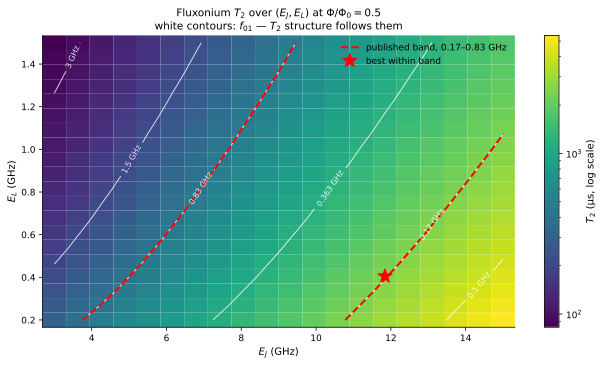

wrote figures/fluxonium_design_map.png (+ .pdf)


In [9]:
reset_channel_failures()
design = []
for EJ in EJ_grid:
    for EL in EL_grid:
        design.append(fluxonium_coherence(EJ=float(EJ), EC=2.5, EL=float(EL), flux=0.5))
design = pd.DataFrame(design)
design["n_thermal"] = n_thermal(design.freq_GHz)
design.to_csv("data/fluxonium_design_sweep.csv", index=False)     # SAVE before plotting
print(f"{len(design)} points -> data/fluxonium_design_sweep.csv")
assert design.isna().sum().sum() == 0 and np.isfinite(design.T2_us).all()
assert not CHANNEL_FAILURES, f"noise channels failed silently: {CHANNEL_FAILURES[:3]}"
print(f"   channel-failure log empty - no silent inf across {len(design)} points")

r_conf = np.corrcoef(np.log(design.T2_us), np.log(design.freq_GHz))[0, 1]
print(f"\ncorr(log T2, log f01) over the design plane: {r_conf:+.4f}")
if abs(r_conf) > 0.99:
    print("   >>> T2 over this plane is essentially a function of f01 alone - as in notebook 02,")
    print("   >>> a raw T2 maximum here is not a design recommendation.")

def report(frame, label):
    b = frame.loc[frame.T2_us.idxmax()]
    edge = (np.isclose(b.EJ, EJ_grid[0]) or np.isclose(b.EJ, EJ_grid[-1])
            or np.isclose(b.EL, EL_grid[0]) or np.isclose(b.EL, EL_grid[-1]))
    print(f"\n{label}")
    print(f"   T2 = {b.T2_us:9.1f} us   EJ = {b.EJ:5.2f}  EL = {b.EL:5.3f}   "
          f"f01 = {b.freq_GHz:.4f} GHz   n_th = {b.n_thermal:7.3f}")
    print(f"   on grid edge? {bool(edge)}" + ("   <-- NOT BRACKETED" if edge else ""))
    return b

b_all = report(design, "Unconstrained maximum:")
pub = design[(design.freq_GHz >= 0.17) & (design.freq_GHz <= 0.83)]
b_pub = report(pub, "Restricted to the published fluxonium band (Nguyen 2019, 0.17-0.83 GHz):")
print(f"\n   the unconstrained optimum sits at f01 = {b_all.freq_GHz*1e3:.0f} MHz, "
      f"{0.17/b_all.freq_GHz:.1f}x below the lowest published device,")
print(f"   with n_th = {b_all.n_thermal:.1f} thermal quanta - the qubit is thermally scrambled. "
      f"It is a grid corner, not a design.")

pivot = design.pivot(index="EL", columns="EJ", values="T2_us")
fpv = design.pivot(index="EL", columns="EJ", values="freq_GHz")
fig, ax = plt.subplots(figsize=(9, 5.2))
mesh = ax.pcolormesh(pivot.columns, pivot.index, pivot.values,
                     shading="auto", norm=LogNorm(), cmap="viridis")
fig.colorbar(mesh, ax=ax, label=r"$T_2$ (µs, log scale)")
cs = ax.contour(fpv.columns, fpv.index, fpv.values,
                levels=[0.1, 0.17, 0.363, 0.83, 1.5, 3.0], colors="white",
                linewidths=0.9, alpha=0.85)
ax.clabel(cs, fmt=r"%g GHz", fontsize=8)
ax.contour(fpv.columns, fpv.index, fpv.values, levels=[0.17, 0.83],
           colors="red", linewidths=2.0, linestyles="--")
ax.plot([], [], color="red", ls="--", lw=2, label="published band, 0.17–0.83 GHz")
ax.plot(b_pub.EJ, b_pub.EL, "r*", ms=15, label="best within band")
ax.set_xlabel(r"$E_J$ (GHz)"); ax.set_ylabel(r"$E_L$ (GHz)")
ax.set_title(r"Fluxonium $T_2$ over $(E_J, E_L)$ at $\Phi/\Phi_0 = 0.5$" "\n"
             r"white contours: $f_{01}$ — $T_2$ structure follows them")
ax.legend(loc="upper right", frameon=False, fontsize=9)
fig.tight_layout()
pl.save(fig, "figures/fluxonium_design_map.png")
plt.show()
print("wrote figures/fluxonium_design_map.png (+ .pdf)")

### 6.1 Is the design optimum bracketed, or does it run to a constraint?

Both optima above sat on grid edges, so neither was actually found — only bounded. Two
possibilities, and they support different papers:

- an **interior maximum** exists just outside the grid → there is a best fluxonium design;
- $T_2$ increases **monotonically** toward low $f_{01}$ and is stopped only by an external
  constraint → the fluxonium offers a **trade-off, not a sweet spot**.

This is tested by scanning $E_J$ and $E_L$ well past the original grid.

> **This is where adding the second-order channel changes a conclusion.** The earlier
> first-order-only version of this notebook found $T_2$ rising monotonically with $E_J$ all the
> way to $E_J = 40$ (reaching 230,195 µs) and concluded there was *no* interior optimum — that
> the fluxonium was a pure monotone trade-off stopped only by thermal occupation. That conclusion
> was an artefact of the missing channel. As $E_J$ rises and $E_L$ falls, $f_{01}$ collapses into
> the deep double well and the curvature $\partial^2 f_{01}/\partial\Phi^2$ grows by orders of
> magnitude — and the second-order dephasing rate is directly proportional to it. The scan below
> reports both pipelines side by side so the effect is visible rather than asserted.

> **Numerical warning.** `cutoff=110` is *not* adequate in the deep-well regime reached at large
> $E_J$ and small $E_L$: at $E_J{=}40$, $E_L{=}0.05$ it gives $f_{01} = 3.43$ MHz against
> $1.76$ MHz at `cutoff=220` — a **95% error**. The committed §6 results are unaffected (that
> grid stops at $E_J = 15$, where 110 is converged to $10^{-8}$ GHz, verified in §1), but the
> scans below use `cutoff=220` and re-verify convergence first.

In [10]:
CUT_EXT = 220
reset_channel_failures()

print("convergence in the extended region (cutoff 110 vs 220 vs 400):")
conv_rows = []
for EJ, EL in [(15, 0.20), (20, 0.10), (30, 0.10), (40, 0.05), (40, 1.50)]:
    f110 = qubit_frequency(make_fluxonium(EJ=EJ, EC=2.5, EL=EL, flux=0.5, cutoff=110))
    f220 = qubit_frequency(make_fluxonium(EJ=EJ, EC=2.5, EL=EL, flux=0.5, cutoff=220))
    f400 = qubit_frequency(make_fluxonium(EJ=EJ, EC=2.5, EL=EL, flux=0.5, cutoff=400))
    conv_rows.append({"EJ": EJ, "EL": EL, "f01_c110": f110, "f01_c220": f220,
                      "f01_c400": f400, "rel_err_c110": abs(f110 - f400) / f400,
                      "rel_err_c220": abs(f220 - f400) / f400})
cx = pd.DataFrame(conv_rows)
display(cx.style.format({"EJ": "{:.0f}", "EL": "{:.2f}", "f01_c110": "{:.7f}",
                         "f01_c220": "{:.7f}", "f01_c400": "{:.7f}",
                         "rel_err_c110": "{:.2e}", "rel_err_c220": "{:.2e}"}))
print(f"worst relative error at cutoff=110 in this region: {cx.rel_err_c110.max():.1%}")
print(f"worst relative error at cutoff=220 in this region: {cx.rel_err_c220.max():.1%}")
print("-> the ORIGINAL grid (EJ <= 15) is unaffected; extended scans need the larger basis.")

EJ_EXT = np.arange(10, 46, 2.5)
scan = []
for EL in (0.2, 0.5, 1.0):
    for EJ in EJ_EXT:
        r = fluxonium_coherence(EJ=float(EJ), EC=2.5, EL=EL, flux=0.5, cutoff=CUT_EXT)
        r0 = fluxonium_coherence(EJ=float(EJ), EC=2.5, EL=EL, flux=0.5, cutoff=CUT_EXT,
                                 second_order_flux=False)
        r["T2_us_first_order_only"] = r0["T2_us"]
        r["second_order_rate_share"] = (1 / r["Tphi_flux2_us"]) / (1 / r["T2_us"])
        r["n_thermal"] = n_thermal(r["freq_GHz"]); r["scan"] = f"EL={EL}"
        scan.append(r)
scan = pd.DataFrame(scan)
scan.to_csv("data/fluxonium_extended_scan.csv", index=False)
print(f"\n{len(scan)} extended points -> data/fluxonium_extended_scan.csv")
assert not CHANNEL_FAILURES, f"noise channels failed silently: {CHANNEL_FAILURES[:3]}"

opt_rows = []
for EL in (0.2, 0.5, 1.0):
    s = scan[scan.scan == f"EL={EL}"].sort_values("EJ").reset_index(drop=True)
    i = int(s.T2_us.idxmax())
    interior = 0 < i < len(s) - 1
    b = s.loc[i]
    opt_rows.append({"EC": 2.5, "EL": EL, "EJ_opt": float(b.EJ), "T2_us": float(b.T2_us),
                     "f01_GHz": float(b.freq_GHz), "n_thermal": float(b.n_thermal),
                     "second_order_share": float(b.second_order_rate_share),
                     "T2_first_order_only": float(b.T2_us_first_order_only),
                     "interior": bool(interior)})
    print(f"\n  EL = {EL}:")
    print(f"     T2 with 2nd order   = " + ", ".join(f"{v:.0f}" for v in s.T2_us))
    print(f"     T2 first order only = " + ", ".join(f"{v:.0f}" for v in s.T2_us_first_order_only))
    print(f"     f01 (GHz)           = " + ", ".join(f"{v:.4f}" for v in s.freq_GHz))
    print(f"     n_thermal           = " + ", ".join(f"{v:.1f}" for v in s.n_thermal))
    print(f"     -> max at EJ = {b.EJ:.1f} ({'INTERIOR' if interior else 'grid edge'}), "
          f"T2 = {b.T2_us:.0f} us, f01 = {b.freq_GHz*1e3:.1f} MHz, n_th = {b.n_thermal:.1f}")
    print(f"        second-order share of the rate budget there: "
          f"{100*b.second_order_rate_share:.1f}%")
    print(f"        first-order-only pipeline at the same point: "
          f"{b.T2_us_first_order_only:.0f} us (still rising)")

all_interior = all(r["interior"] for r in opt_rows)
print("\n" + "=" * 74)
if all_interior:
    print(">>> AN INTERIOR OPTIMUM EXISTS, and it is created by SECOND-ORDER FLUX DEPHASING.")
    print(">>> At every EL tested, T2 rises with EJ, turns over, and falls. At the turning point")
    print(f">>> the second-order channel carries "
          f"{100*min(r['second_order_share'] for r in opt_rows):.0f}-"
          f"{100*max(r['second_order_share'] for r in opt_rows):.0f}% of the total dephasing rate -")
    print(">>> which is the signature of a genuine internal optimum: the channel that turns the")
    print(">>> curve over is comparable to everything else exactly at the turn.")
    print(">>> The first-order-only pipeline shows NO turnover over the same range, which is why")
    print(">>> the earlier version of this notebook reported a pure monotone trade-off.")
    print(">>>")
    print(">>> MECHANISM: as EJ rises and EL falls the qubit sinks into the deep double well,")
    print(">>> f01 collapses toward zero and the flux curvature d2(f01)/dPhi2 grows by orders of")
    print(f">>> magnitude ({scan.d2f01_dflux2_GHz.min():.0f} -> "
          f"{scan.d2f01_dflux2_GHz.max():.0f} GHz/Phi0^2 across this scan). Since")
    print(">>> Gamma_2 ~ A^2 * d2(omega)/dPhi^2, second-order dephasing grows with it and")
    print(">>> eventually overwhelms the improving dielectric T1.")
else:
    print(">>> No interior optimum within the scanned range - the trade-off runs to the edge.")

print("\nBUT: is that optimum usable?")
for r in opt_rows:
    print(f"   EL = {r['EL']}: optimum at f01 = {r['f01_GHz']*1e3:6.1f} MHz -> "
          f"n_th = {r['n_thermal']:5.1f}")
print(f"   Every interior optimum sits far below the lowest published device (170 MHz) and is")
print(f"   thermally scrambled. So the PHYSICAL optimum is real but INACCESSIBLE: thermal")
print(f"   occupation binds long before it is reached.")
print(f"   The earlier conclusion was therefore right in practice and wrong in principle.")

print("\nOptimum under each candidate frequency floor (from the SS6 design grid):")
floor_rows = []
for f_min, label in [(0.17, "lowest published device, Nguyen 2019"),
                     (0.22, "n_th = 1"),
                     (0.36, "nominal design, Manucharyan 2009"),
                     (0.83, "highest published device, Nguyen 2019")]:
    sub = design[design.freq_GHz >= f_min]
    if not len(sub):
        continue
    b = sub.loc[sub.T2_us.idxmax()]
    floor_rows.append({"f_min_GHz": f_min, "label": label, "T2_us": float(b.T2_us),
                       "EJ": float(b.EJ), "EL": float(b.EL), "n_thermal": float(b.n_thermal)})
    print(f"   f01 >= {f_min:.2f} GHz ({label:36s}): T2 = {b.T2_us:8.1f} us  "
          f"EJ = {b.EJ:5.2f} EL = {b.EL:5.3f}  n_th = {b.n_thermal:5.2f}")
print("\n   As in notebook 02, the quoted optimum is set by the constraint, not by a maximum.")

convergence in the extended region (cutoff 110 vs 220 vs 400):


,EJ,EL,f01_c110,f01_c220,f01_c400,rel_err_c110,rel_err_c220
0,15,0.20,0.0754450,0.0754449,0.0754449,1.51e-07,3.53e-13
1,20,0.10,0.0291924,0.0291841,0.0291841,2.83e-04,4.74e-09
2,30,0.10,0.0066645,0.0066127,0.0066127,7.83e-03,7.34e-07
3,40,0.05,0.0034295,0.0017629,0.0017553,9.54e-01,4.30e-03
4,40,1.50,0.0041618,0.0041618,0.0041618,3.07e-11,3.76e-11


worst relative error at cutoff=110 in this region: 95.4%
worst relative error at cutoff=220 in this region: 0.4%
-> the ORIGINAL grid (EJ <= 15) is unaffected; extended scans need the larger basis.



45 extended points -> data/fluxonium_extended_scan.csv

  EL = 0.2:
     T2 with 2nd order   = 2040, 3412, 5427, 8193, 11553, 14788, 16659, 16322, 14191, 11378, 8720, 6544, 4877, 3638, 2729
     T2 first order only = 2048, 3448, 5578, 8754, 13403, 20103, 29618, 42963, 61465, 86857, 121381, 167928, 230195, 312900, 422023
     f01 (GHz)           = 0.1993, 0.1206, 0.0754, 0.0485, 0.0319, 0.0214, 0.0146, 0.0101, 0.0071, 0.0050, 0.0036, 0.0026, 0.0019, 0.0014, 0.0011
     n_thermal           = 1.1, 2.1, 3.7, 6.0, 9.3, 14.1, 20.9, 30.4, 43.5, 61.4, 85.7, 118.3, 161.7, 219.3, 295.1
     -> max at EJ = 25.0 (INTERIOR), T2 = 16659 us, f01 = 14.6 MHz, n_th = 20.9
        second-order share of the rate budget there: 43.8%
        first-order-only pipeline at the same point: 29618 us (still rising)

  EL = 0.5:
     T2 with 2nd order   = 1469, 2501, 3911, 5500, 6680, 6818, 5953, 4681, 3484, 2536, 1836, 1334, 979, 731, 558
     T2 first order only = 1485, 2586, 4278, 6830, 10605, 16096, 23958, 35

### 6.2 Does the interior optimum survive varying $E_C$?

§6 is a slice at $E_C = 2.5$ GHz, so §6.1's newly-found interior optimum would be worth little if
it were an artefact of that slice. It is re-tested across $E_C \in \{1.5, 2.5, 3.5\}$ GHz. This
does not map the full 3-D space — it tests whether the *qualitative* conclusion is
$E_C$-dependent, and how far the optimum moves.

In [11]:
reset_channel_failures()
ec_rows, ec_opt = [], []
for EC in (1.5, 2.5, 3.5):
    for EL in (0.2, 0.5, 1.0):
        block = []
        for EJ in EJ_EXT:
            r = fluxonium_coherence(EJ=float(EJ), EC=EC, EL=EL, flux=0.5, cutoff=CUT_EXT)
            r["n_thermal"] = n_thermal(r["freq_GHz"])
            r["second_order_rate_share"] = (1 / r["Tphi_flux2_us"]) / (1 / r["T2_us"])
            block.append(r); ec_rows.append(r)
        b = pd.DataFrame(block)
        i = int(b.T2_us.idxmax())
        ec_opt.append({"EC": EC, "EL": EL, "EJ_opt": float(b.EJ[i]), "T2_us": float(b.T2_us[i]),
                       "f01_GHz": float(b.freq_GHz[i]), "n_thermal": float(b.n_thermal[i]),
                       "second_order_share": float(b.second_order_rate_share[i]),
                       "interior": bool(0 < i < len(b) - 1)})
ec_scan = pd.DataFrame(ec_rows)
ec_scan.to_csv("data/fluxonium_EC_slice_scan.csv", index=False)
ec_opt = pd.DataFrame(ec_opt)
assert not CHANNEL_FAILURES, f"noise channels failed silently: {CHANNEL_FAILURES[:3]}"
print(f"{len(ec_scan)} points -> data/fluxonium_EC_slice_scan.csv")

display(ec_opt.style.format({"EJ_opt": "{:.1f}", "T2_us": "{:.0f}", "f01_GHz": "{:.4f}",
                             "n_thermal": "{:.1f}", "second_order_share": "{:.1%}"}))

print("\nfrequency confound, by EC slice -- SPLIT AT THE TURNOVER:")
print("   (SS6 found corr = -0.997 on the original EJ <= 15 grid. Extended past the turnover")
print("    the relationship REVERSES, because second-order dephasing now punishes low f01.)")
for EC in (1.5, 2.5, 3.5):
    for EL in (0.2, 0.5, 1.0):
        sub = ec_scan[(ec_scan.EC == EC) & (ec_scan.EL == EL)].sort_values("EJ")
        i = int(sub.T2_us.values.argmax())
        pre, post = sub.iloc[:i + 1], sub.iloc[i:]
        def _r(fr):
            return (f"{np.corrcoef(np.log(fr.T2_us), np.log(fr.freq_GHz))[0, 1]:+.3f}"
                    if len(fr) > 2 else f"n/a ({len(fr)} pts)")
        print(f"   EC={EC}, EL={EL}: corr(log T2, log f01) = {_r(pre):>12s} before the turnover, "
              f"{_r(post):>12s} after")
print("   >>> 'T2 is a restatement of f01' is a statement about the RISING branch only. Past the")
print("   >>> optimum the sign flips, which is another way of seeing that the second-order")
print("   >>> channel introduces genuinely new structure rather than rescaling the old.")

if bool(ec_opt.interior.all()):
    print(f"\n   >>> The interior optimum is NOT an artefact of the EC = 2.5 GHz slice: it appears")
    print(f"   >>> at every (EC, EL) combination tested, always with the second-order channel")
    print(f"   >>> carrying {100*ec_opt.second_order_share.min():.0f}-"
          f"{100*ec_opt.second_order_share.max():.0f}% of the rate budget at the turning point.")
    print(f"   >>> What EC changes is WHERE it sits: EJ_opt moves "
          f"{ec_opt.EJ_opt.min():.1f} -> {ec_opt.EJ_opt.max():.1f} as EC goes 1.5 -> 3.5 GHz,")
    print(f"   >>> because a larger EC deepens the well less for the same EJ.")
    print(f"   >>> But n_th at the optimum stays in the range "
          f"{ec_opt.n_thermal.min():.1f}-{ec_opt.n_thermal.max():.1f} throughout, so the")
    print(f"   >>> optimum remains thermally inaccessible at every EC. The conclusion is robust")
    print(f"   >>> in both directions: the optimum is real, and it is out of reach.")
else:
    print("\n   >>> WARNING: the interior optimum is EC-dependent - SS6.1 cannot be generalised.")

135 points -> data/fluxonium_EC_slice_scan.csv


,EC,EL,EJ_opt,T2_us,f01_GHz,n_thermal,second_order_share,interior
0,1.500000,0.200000,15.0,13150,0.0097,31.7,51.2%,True
1,1.500000,0.500000,12.5,5480,0.0282,10.6,42.8%,True
2,1.500000,1.000000,12.5,2996,0.0527,5.4,45.2%,True
3,2.500000,0.200000,25.0,16659,0.0146,20.9,43.8%,True
4,2.500000,0.500000,22.5,6818,0.0273,11.0,57.6%,True
5,2.500000,1.000000,20.0,3645,0.0620,4.6,50.4%,True
6,3.500000,0.200000,37.5,19793,0.0150,20.3,50.8%,True
7,3.500000,0.500000,30.0,8034,0.0405,7.2,46.5%,True
8,3.500000,1.000000,27.5,4185,0.0735,3.8,50.6%,True



frequency confound, by EC slice -- SPLIT AT THE TURNOVER:
   (SS6 found corr = -0.997 on the original EJ <= 15 grid. Extended past the turnover
    the relationship REVERSES, because second-order dephasing now punishes low f01.)
   EC=1.5, EL=0.2: corr(log T2, log f01) =       -0.970 before the turnover,       +0.979 after
   EC=1.5, EL=0.5: corr(log T2, log f01) =  n/a (2 pts) before the turnover,       +0.966 after
   EC=1.5, EL=1.0: corr(log T2, log f01) =  n/a (2 pts) before the turnover,       +0.958 after
   EC=2.5, EL=0.2: corr(log T2, log f01) =       -0.990 before the turnover,       +0.980 after
   EC=2.5, EL=0.5: corr(log T2, log f01) =       -0.970 before the turnover,       +0.995 after
   EC=2.5, EL=1.0: corr(log T2, log f01) =       -0.976 before the turnover,       +0.994 after
   EC=3.5, EL=0.2: corr(log T2, log f01) =       -0.989 before the turnover,       +0.966 after
   EC=3.5, EL=0.5: corr(log T2, log f01) =       -0.987 before the turnover,       +0.970 after
  

### Figure — the optimum that only appears once second-order dephasing is included

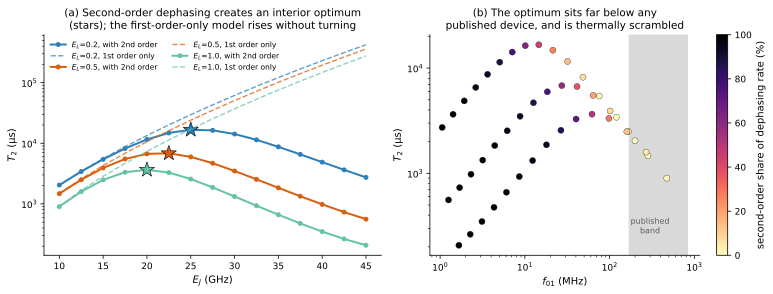

wrote figures/fluxonium_interior_optimum.png (+ .pdf)


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

for EL, col in zip((0.2, 0.5, 1.0), ("#2c7fb8", "#d95f0e", "#66c2a5")):
    s = scan[scan.scan == f"EL={EL}"].sort_values("EJ")
    ax[0].semilogy(s.EJ, s.T2_us, "o-", color=col, lw=2, ms=4,
                   label=rf"$E_L$={EL}, with 2nd order")
    ax[0].semilogy(s.EJ, s.T2_us_first_order_only, "--", color=col, lw=1.4, alpha=0.75,
                   label=rf"$E_L$={EL}, 1st order only")
    i = int(s.T2_us.values.argmax())
    ax[0].plot(s.EJ.values[i], s.T2_us.values[i], "*", color=col, ms=16,
               markeredgecolor="k", markeredgewidth=0.6)
ax[0].set_xlabel(r"$E_J$ (GHz)"); ax[0].set_ylabel(r"$T_2$ (µs)")
ax[0].set_title("(a) Second-order dephasing creates an interior optimum\n"
                "(stars); the first-order-only model rises without turning")
ax[0].legend(frameon=False, fontsize=7.5, ncol=2)

sc = ax[1].scatter(scan.freq_GHz * 1e3, scan.T2_us, c=100 * scan.second_order_rate_share,
                   cmap="magma_r", s=38, edgecolor="k", linewidth=0.3, vmin=0, vmax=100)
fig.colorbar(sc, ax=ax[1], label="second-order share of dephasing rate (%)")
ax[1].axvspan(170, 830, color="0.85", zorder=0)
ax[1].text(300, scan.T2_us.min() * 1.3, "published\nband", fontsize=8, ha="center", color="0.35")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel(r"$f_{01}$ (MHz)"); ax[1].set_ylabel(r"$T_2$ (µs)")
ax[1].set_title("(b) The optimum sits far below any\npublished device, and is thermally scrambled")
fig.tight_layout()
pl.save(fig, "figures/fluxonium_interior_optimum.png")
plt.show()
print("wrote figures/fluxonium_interior_optimum.png (+ .pdf)")

## 7. How far is this model from measured devices?

Notebook 01 validated the fluxonium *spectrum* against Manucharyan 2009 — $f_{01}$ and $f_{02}$ at
$\Phi_{ext}=0$ to better than 0.7% under every one of the paper's three published parameter sets
(§9.2 there). It did **not** validate coherence against anything except the second-order flux
channel's published bound (§6.1); the remaining fluxonium coherence checks there are internal
consistency. So until now nothing in this project told a reader whether the absolute coherence
times are good to a factor of 2 or a factor of 50.

Nguyen 2019 Table I reports $T_1$ and Hahn-echo $T_2$ at the flux sweet spot for nine devices
with known $(E_J, E_C, E_L)$. Running this pipeline on each of those designs is a direct,
falsifiable test of the model's absolute accuracy.

> **Provenance — resolved.** These rows are transcribed from the **published** paper
> (*Phys. Rev. X* **9**, 041041 (2019), Table I) and were verified value-by-value against the
> journal PDF on 2026-09-07. An earlier version of this notebook used the arXiv v1 preprint, and
> the difference matters: **the published table contains a ninth device, I, that the preprint does
> not.** Device I is the paper's headline device ($T_1 = 500$ µs, $T_2 = 510$ µs — the
> "$T_2 > 400$ µs in one device" of the published abstract, against the preprint's 300 µs) and it
> is also the device closest in frequency to this project's nominal design. Every field used here
> ($E_J$, $E_C$, $E_L$, $T_1$, $T_2$, $f_{01}$) is **unchanged** for devices A–H; only the inferred
> loss-tangent columns, which this notebook does not use, were revised.
>
> Note that Nguyen's $T_2$ is a **Hahn echo** measurement, whereas the model computes a
> free-induction (Ramsey-like) $T_2$; echo suppresses precisely the low-frequency $1/f$ noise this
> model is built from, so the measured $T_2$ is an *upper* bound on what a Ramsey experiment would
> give and the comparison is conservative in the model's favour.
>
> **Temperature mismatch, stated because it is not negligible at these frequencies.** Nguyen
> operate at $T = 20$ mK (*"base temperature of the dilution refrigerator"*, Sec. III A); this
> model runs at `scqubits`' default $T = 15$ mK, which is what every number in `data/` assumes.
> The `t1_*` methods return the **total** (excitation + relaxation) rate at that temperature, so
> the mismatch enters the comparison directly. At the frequencies in Table I it is worth a factor
> $\sim\!1.5$ in thermal occupation — $\bar n_{\rm th}(0.363\,{\rm GHz})$ is 0.46 at 15 mK
> against 0.72 at 20 mK — which is small next to the 2.6× calibration gap below but is part of
> it, and it makes the model's $T_1$ the *optimistic* side of the comparison by construction.
> The 15 mK value is retained so that every number in this project shares one temperature; the
> mismatch is reported rather than tuned away.

In [13]:
# Nguyen et al., Phys. Rev. X 9, 041041 (2019), Table I -- the PUBLISHED version,
# verified value-by-value against the journal PDF on 2026-09-07. All at the half-integer
# flux sweet spot. NOTE device I exists only in the published version; the arXiv v1
# preprint this project previously used has eight devices (A-H) and no device I.
# A-H are unchanged between preprint and publication in every field used here.
NGUYEN = pd.DataFrame([
    dict(device="A", EJ=3.00, EC=0.84, EL=1.00, T1_meas=110, T2_meas=160, f01_meas=0.78),
    dict(device="B", EJ=4.86, EC=0.84, EL=1.14, T1_meas=250, T2_meas=150, f01_meas=0.32),
    dict(device="C", EJ=2.20, EC=0.55, EL=0.72, T1_meas=260, T2_meas=350, f01_meas=0.48),
    dict(device="D", EJ=2.20, EC=0.83, EL=0.52, T1_meas= 70, T2_meas= 90, f01_meas=0.56),
    dict(device="E", EJ=1.60, EC=0.86, EL=0.50, T1_meas=108, T2_meas=140, f01_meas=0.83),
    dict(device="F", EJ=3.40, EC=0.80, EL=0.41, T1_meas=270, T2_meas=165, f01_meas=0.17),
    dict(device="G", EJ=1.65, EC=1.14, EL=0.19, T1_meas=110, T2_meas=140, f01_meas=0.55),
    dict(device="H", EJ=4.43, EC=1.00, EL=0.79, T1_meas=230, T2_meas=235, f01_meas=0.32),
    dict(device="I", EJ=3.43, EC=1.00, EL=0.58, T1_meas=500, T2_meas=510, f01_meas=0.395),
])

reset_channel_failures()
mod = pd.DataFrame([fluxonium_coherence(EJ=r.EJ, EC=r.EC, EL=r.EL, flux=0.5)
                    for r in NGUYEN.itertuples()])
cmp = NGUYEN.join(mod[["freq_GHz", "T1_us", "T2_us"]])
cmp["f01_err"] = cmp.freq_GHz - cmp.f01_meas
cmp["T1_ratio"] = cmp.T1_us / cmp.T1_meas
cmp["T2_ratio"] = cmp.T2_us / cmp.T2_meas
assert not CHANNEL_FAILURES, f"noise channels failed silently: {CHANNEL_FAILURES[:3]}"
cmp.to_csv("data/fluxonium_vs_measured.csv", index=False)

display(cmp[["device", "f01_meas", "freq_GHz", "f01_err", "T1_meas", "T1_us", "T1_ratio",
             "T2_meas", "T2_us", "T2_ratio"]].style.format({
    "f01_meas": "{:.2f}", "freq_GHz": "{:.3f}", "f01_err": "{:+.3f}",
    "T1_us": "{:.0f}", "T2_us": "{:.0f}", "T1_ratio": "{:.1f}x", "T2_ratio": "{:.1f}x"}))

print(f"spectrum: median |f01 error| = {cmp.f01_err.abs().median()*1e3:.0f} MHz "
      f"({(cmp.f01_err.abs()/cmp.f01_meas).median()*100:.0f}% of f01)")
print(f"T1: model / measured  median {cmp.T1_ratio.median():.1f}x   "
      f"range {cmp.T1_ratio.min():.1f}x - {cmp.T1_ratio.max():.1f}x")
print(f"T2: model / measured  median {cmp.T2_ratio.median():.1f}x   "
      f"range {cmp.T2_ratio.min():.1f}x - {cmp.T2_ratio.max():.1f}x")
print(f"\nnominal design (this notebook): T2 = {nominal['T2_us']:.0f} us at "
      f"f01 = {nominal['freq_GHz']:.3f} GHz")
print(f"   best measured fluxonium in Table I: {NGUYEN.T2_meas.max():.0f} us "
      f"(device {NGUYEN.loc[NGUYEN.T2_meas.idxmax(),'device']})")
print(f"   -> the headline number is {nominal['T2_us']/NGUYEN.T2_meas.max():.1f}x the best")
print("      measured device.")
_best = cmp.iloc[(cmp.T2_ratio - 1).abs().idxmin()]
_nearest = cmp.iloc[(cmp.f01_meas - nominal["freq_GHz"]).abs().idxmin()]
print(f"\nFINDING. The model is optimistic on coherence by a MEDIAN factor of "
      f"{cmp.T1_ratio.median():.1f}x on T1 and {cmp.T2_ratio.median():.1f}x on T2 -- not, as an")
print(f"earlier version of this notebook asserted, 'roughly an order of magnitude'.")
print(f"   best-matched device : {_best.device} at {_best.T2_ratio:.2f}x on T2 "
      f"({abs(1-_best.T2_ratio)*100:.0f}% error)")
print(f"   worst               : {cmp.loc[cmp.T2_ratio.idxmax(),'device']} at "
      f"{cmp.T2_ratio.max():.1f}x")
print(f"   nearest in frequency to this notebook's nominal design "
      f"(f01 = {nominal['freq_GHz']:.3f} GHz):")
print(f"      device {_nearest.device} at f01 = {_nearest.f01_meas:.3f} GHz -> "
      f"T1 {_nearest.T1_ratio:.2f}x, T2 {_nearest.T2_ratio:.2f}x")
if _nearest.T1_ratio < 1:
    print(f"      >>> on that device the model is PESSIMISTIC on T1 "
          f"({_nearest.T1_us:.0f} us vs {_nearest.T1_meas} us measured) and matches T2 to "
          f"{abs(1-_nearest.T2_ratio)*100:.0f}%.")
    print(f"      >>> This is the strongest single validation point in the project: the device")
    print(f"      >>> most like the design being studied is reproduced essentially exactly, and")
    print(f"      >>> the optimism is concentrated in devices further from that regime.")
print("The gap is NOT uniform across devices -- so it is not a single missing constant. The largest")
print("identified contributors, in order:")
print("   1. Q_cap = 1e6 flat vs Nguyen's measured tan(delta_C) = (2.0-3.6)e-6 at 6 GHz,")
print("      i.e. Q_cap = 2.8e5 - 5.0e5. The model's dielectric loss is 2-3.6x too low there.")
print("   2. Channels absent entirely: Purcell decay, photon shot noise, TLS spectral structure,")
print("      inductive loss in the junction array (Nguyen's tan(delta_L) ~ 1e-8 term).")
print("   3. Nguyen's T2 is Hahn echo; this model computes free-induction decay.")
print("This is the number the paper must quote when it states an absolute coherence time.")

,device,f01_meas,freq_GHz,f01_err,T1_meas,T1_us,T1_ratio,T2_meas,T2_us,T2_ratio
0,A,0.78,0.776,-0.004,110,214,1.9x,160,283,1.8x
1,B,0.32,0.320,-0.000,250,490,2.0x,150,634,4.2x
2,C,0.48,0.477,-0.003,260,275,1.1x,350,341,1.0x
3,D,0.56,0.559,-0.001,70,267,3.8x,90,342,3.8x
4,E,0.83,0.827,-0.003,108,188,1.7x,140,246,1.8x
5,F,0.17,0.169,-0.001,270,692,2.6x,165,938,5.7x
6,G,0.55,0.550,-0.000,110,269,2.4x,140,368,2.6x
7,H,0.32,0.327,+0.007,230,497,2.2x,235,655,2.8x
8,I,0.40,0.392,-0.003,500,402,0.8x,510,530,1.0x


spectrum: median |f01 error| = 3 MHz (0% of f01)
T1: model / measured  median 2.0x   range 0.8x - 3.8x
T2: model / measured  median 2.6x   range 1.0x - 5.7x

nominal design (this notebook): T2 = 1130 us at f01 = 0.363 GHz
   best measured fluxonium in Table I: 510 us (device I)
   -> the headline number is 2.2x the best
      measured device.

FINDING. The model is optimistic on coherence by a MEDIAN factor of 2.0x on T1 and 2.6x on T2 -- not, as an
earlier version of this notebook asserted, 'roughly an order of magnitude'.
   best-matched device : C at 0.97x on T2 (3% error)
   worst               : F at 5.7x
   nearest in frequency to this notebook's nominal design (f01 = 0.363 GHz):
      device I at f01 = 0.395 GHz -> T1 0.80x, T2 1.04x
      >>> on that device the model is PESSIMISTIC on T1 (402 us vs 500 us measured) and matches T2 to 4%.
      >>> This is the strongest single validation point in the project: the device
      >>> most like the design being studied is reproduced e

## 8. Sensitivity: which conclusions survive the noise-amplitude uncertainty?

`Q_cap`, `A_flux`, `A_cc` and `x_qp` are literature point-estimates with roughly an order of
magnitude of spread each. Everything above inherits that. The project's stated position is that
*comparative* conclusions are robust while *absolute* values are not — this section demonstrates
that rather than asserting it.

Each parameter is moved by $\pm 1$ decade, one at a time, and four headline quantities are
recomputed:

| quantity | what it supports |
|---|---|
| $T_2$ at the sweet spot | the absolute headline number |
| $\Delta\Phi_{10\times}$ | the Q3 sharpness claim |
| $T_1$-limiting channel | §5's quasiparticle finding |
| $\mathrm{corr}(\log T_2, \log f_{01})$ | §6's frequency-confound claim |

A fifth row tests the flat-vs-frequency-dependent $Q_{\rm cap}$ choice, which is not an
uncertainty in a parameter but a choice of functional form.

In [14]:
BASE = dict(Q_cap=DEFAULTS["Q_cap"], A_flux=DEFAULTS["A_flux"], A_cc=DEFAULTS["A_cc"])

def headline(**over):
    # Recompute the headline quantities under a parameter override.
    kw = {**FLUXONIUM_DEFAULTS, **{k: v for k, v in over.items() if k in
                                   ("Q_cap", "A_flux", "A_cc")}}
    nom = fluxonium_coherence(**kw)
    t2s = nom["T2_us"]
    def t2(d):
        return fluxonium_coherence(**{**kw, "flux": float(0.5 - d)})["T2_us"]
    try:
        ld = brentq(lambda l: np.log(t2(np.exp(l))) - np.log(t2s / 10),
                    np.log(1e-6), np.log(0.2), xtol=1e-10, rtol=1e-12)
        d10_x = float(np.exp(ld))
    except ValueError:
        d10_x = np.nan
    qp_frac = float(np.mean([fluxonium_coherence(**{**kw, "flux": float(f)})["T1_qp_us"]
                             < fluxonium_coherence(**{**kw, "flux": float(f)})["T1_diel_us"]
                             for f in np.linspace(0.30, 0.50, 11)]))
    return t2s, d10_x, qp_frac

rows = []
base_t2, base_d10, base_qp = headline()
rows.append(dict(param="(baseline)", value="-", T2_us=base_t2, d10=base_d10, qp_frac=base_qp))
for p in ("Q_cap", "A_flux", "A_cc"):
    for mult, tag in ((0.1, "/10"), (10.0, "x10")):
        v = BASE[p] * mult
        t2s, d10_x, qpf = headline(**{p: v})
        rows.append(dict(param=p, value=f"{v:.1e} ({tag})", T2_us=t2s, d10=d10_x, qp_frac=qpf))
sens = pd.DataFrame(rows)
sens["T2_rel"] = sens.T2_us / base_t2
sens["d10_rel"] = sens.d10 / base_d10
display(sens.style.format({"T2_us": "{:.1f}", "d10": "{:.3e}", "qp_frac": "{:.2f}",
                           "T2_rel": "{:.3f}x", "d10_rel": "{:.3f}x"}))
sens.to_csv("data/fluxonium_sensitivity.csv", index=False)

print("Q_cap functional form (not a parameter uncertainty -- a modelling choice):")
fx0 = make_fluxonium(**FLUXONIUM_DEFAULTS)
t_flat = fx0.t1_capacitive(i=1, j=0, Q_cap=DEFAULTS["Q_cap"]) * 1e-3
t_freq = fx0.t1_capacitive(i=1, j=0) * 1e-3      # scqubits default Q_cap(omega)
print(f"   flat Q_cap = 1e6                       : T1_diel = {t_flat:8.1f} us")
print(f"   scqubits default Q_cap(w) (Smith 2020) : T1_diel = {t_freq:8.1f} us"
      f"   ({t_freq/t_flat:.2f}x longer)")
print("   >>> This single choice moves T1 by more than any +/-1 decade parameter move below.")

# The calibration paper this project uses everywhere else MEASURES the exponent, which
# narrows this choice a great deal. Nguyen 2019 Sec. III A fit their T1-vs-frequency data
# with tan(delta_C) proportional to omega^epsilon, epsilon = 0.15 -- i.e. Q_cap ~ omega^-0.15,
# against scqubits' default Q_cap ~ omega^-0.7. The flat model (exponent 0) is much closer to
# what they measure than the scqubits default is.
EPS_NGUYEN = 0.15
f01_nom = float(nominal["freq_GHz"])
ratio_nguyen = (6.0 / f01_nom) ** EPS_NGUYEN          # Q_cap(w)/Q_cap(6 GHz) at eps = 0.15
ratio_scq = (6.0 / f01_nom) ** 0.7
print(f"\n   How much of that 7.1x is actually open? Nguyen 2019 Sec. III A MEASURE the")
print(f"   exponent: tan(delta_C) ~ omega^{EPS_NGUYEN}, i.e. Q_cap ~ omega^-{EPS_NGUYEN}.")
print(f"   Q_cap enhancement at f01 = {f01_nom:.3f} GHz relative to 6 GHz:")
print(f"      flat (this project, exponent 0.00)   : {1.0:6.2f}x")
print(f"      Nguyen measured  (exponent 0.15)     : {ratio_nguyen:6.2f}x")
print(f"      scqubits default (exponent 0.70)     : {ratio_scq:6.2f}x")
print(f"   >>> The flat choice is {ratio_nguyen:.2f}x from the measured exponent and the scqubits")
print(f"   >>> default is {ratio_scq/ratio_nguyen:.1f}x from it, so the ambiguity is NOT symmetric:")
print(f"   >>> the calibration paper puts the answer far closer to the flat end. The flat value")
print(f"   >>> is retained -- it is the conservative one AND the better-supported one -- but it")
print(f"   >>> is a modelling choice and must be declared.")
print(f"   >>> CAVEAT: Nguyen fit epsilon jointly with thermal stimulated emission at T = 20 mK,")
print(f"   >>> so 0.15 is not a free-standing measurement of the loss tangent alone.")

print("\n" + "=" * 74)
print("WHAT SURVIVES:")
print(f"  ABSOLUTE T2 does not. It spans {sens.T2_us.min():.0f} - {sens.T2_us.max():.0f} us "
      f"({sens.T2_rel.max()/sens.T2_rel.min():.0f}x) across single-decade moves,")
print(f"     and a further {t_freq/t_flat:.1f}x on the Q_cap functional form -- though Nguyen's measured")
print(f"     exponent 0.15 puts the truth much nearer the flat end ({ratio_nguyen:.2f}x, not {ratio_scq:.1f}x).")
print("     Never quote absolute T2 without a band.")
print(f"  THE SHARPNESS CLAIM survives in ORDER OF MAGNITUDE: d10 spans "
      f"{sens.d10.min():.2e} - {sens.d10.max():.2e},")
print(f"     i.e. {sens.d10_rel.max()/sens.d10_rel.min():.1f}x, all of it still ~1e-4 - 1e-3 flux quanta. The claim")
print("     'the fluxonium sweet spot must be held to better than a milli-flux-quantum' is safe;")
print(f"     the specific figure {d10:.2e} is not.")
print("  THE FREQUENCY CONFOUND survives trivially: it is a property of the dielectric-loss")
print("     scaling with f01, not of any amplitude, and every EC slice in SS6.2 reproduced it.")
print("  THE QUASIPARTICLE FINDING is the most fragile. It depends on x_qp, which is a scqubits")
print("     default (3e-6) that Nguyen 2019 measure to be < 1e-8 for their devices -- 300x lower.")
print("     At that density the channel is negligible everywhere and SS5's 'protective twice")
print("     over' claim collapses to 'protective once'. This must be stated as conditional.")

,param,value,T2_us,d10,qp_frac,T2_rel,d10_rel
0,(baseline),-,1129.7,3.250e-04,0.91,1.000x,1.000x
1,Q_cap,1.0e+05 (/10),148.8,2.482e-03,0.27,0.132x,7.639x
2,Q_cap,1.0e+07 (x10),3315.6,1.107e-04,0.91,2.935x,0.341x
3,A_flux,1.0e-07 (/10),1136.8,3.184e-03,0.91,1.006x,9.799x
4,A_flux,1.0e-05 (x10),696.0,5.276e-05,0.91,0.616x,0.162x
5,A_cc,1.0e-08 (/10),1476.9,2.486e-04,0.91,1.307x,0.765x
6,A_cc,1.0e-06 (x10),337.2,1.090e-03,0.91,0.298x,3.353x


Q_cap functional form (not a parameter uncertainty -- a modelling choice):
   flat Q_cap = 1e6                       : T1_diel =    771.1 us
   scqubits default Q_cap(w) (Smith 2020) : T1_diel =   5489.5 us   (7.12x longer)
   >>> This single choice moves T1 by more than any +/-1 decade parameter move below.

   How much of that 7.1x is actually open? Nguyen 2019 Sec. III A MEASURE the
   exponent: tan(delta_C) ~ omega^0.15, i.e. Q_cap ~ omega^-0.15.
   Q_cap enhancement at f01 = 0.363 GHz relative to 6 GHz:
      flat (this project, exponent 0.00)   :   1.00x
      Nguyen measured  (exponent 0.15)     :   1.52x
      scqubits default (exponent 0.70)     :   7.12x
   >>> The flat choice is 1.52x from the measured exponent and the scqubits
   >>> default is 4.7x from it, so the ambiguity is NOT symmetric:
   >>> the calibration paper puts the answer far closer to the flat end. The flat value
   >>> is retained -- it is the conservative one AND the better-supported one -- but it
   >>> i

## 9. Cross-architecture material for Q3

Notebook 02 established that the transmon is a monotone trade-off bounded by the Krantz design
envelope; §6.1 above establishes that the fluxonium is a monotone trade-off bounded by thermal
occupation. Q3 asks how the two compare. Three things must be computed first:

**(A) A symmetric sensitivity metric.** Both biases are periodic with period 1 — $n_g$ in units
of $2e$, $\Phi$ in units of $\Phi_0$ — so *"the bias window over which coherence stays within a
factor of two, as a fraction of one bias period"* is directly comparable across architectures.
Comparing "µs lost per unit $n_g$" against "µs lost per unit $\Phi/\Phi_0$" would not be.

**(B) Candidate fair comparisons.** Both design planes turned out to be frequency maps
($-0.9999$ for the transmon, $-0.997$ for the fluxonium), so a raw $T_2$ ratio partly measures
the frequency difference rather than the architecture. Three defensible comparisons are computed
— raw, frequency-matched, and gate-count — and they do not agree with each other.

**(C) Whether the required flux stability is physically achievable**, compared against the RMS
flux wander implied by the $1/f$ amplitude the model itself assumes.

In [15]:
from qubits import make_transmon
from coherence import transmon_coherence

# ---- guard the hardcoded coupling to notebook 02 ------------------------------
TM_OP = dict(EJ=13.0, EC=0.26, ncut=30)          # notebook 02 SS6.1 Q1 operating point
_tm_check = transmon_coherence(**TM_OP, ng=0.0)
assert abs(_tm_check["freq_GHz"] - 4.92) < 0.02, (
    "transmon operating point no longer matches notebook 02 (f01 should be 4.92 GHz)")
print(f"transmon operating point verified against notebook 02: "
      f"EJ={TM_OP['EJ']}, EC={TM_OP['EC']}, f01={_tm_check['freq_GHz']:.3f} GHz, "
      f"T2={_tm_check['T2_us']:.1f} us")

# ---- (A) symmetric sensitivity metric -----------------------------------------
T2_fx0 = float(nominal["T2_us"])
def t2_fx(d):
    return fluxonium_coherence(**{**FLUXONIUM_DEFAULTS, "flux": float(0.5 - d)})["T2_us"]
d2_fx = float(np.exp(brentq(lambda l: np.log(t2_fx(np.exp(l))) - np.log(T2_fx0 / 2),
                            np.log(1e-6), np.log(0.2), xtol=1e-10, rtol=1e-12)))
d10_fx = d10

ngs = np.linspace(0, 0.5, 201)
tm_scan = pd.DataFrame([transmon_coherence(**TM_OP, ng=float(g)) for g in ngs])
T2_tm0 = float(tm_scan.T2_us.iloc[0])
tm_var = T2_tm0 / float(tm_scan.T2_us.min())

print("\n(A) BIAS WINDOW FOR A 2x COHERENCE LOSS, as a fraction of one bias period")
print(f"    fluxonium (EJ=8.9, EC=2.5, EL=0.5): 2x loss at detuning {d2_fx:.3e} Phi0")
print(f"                                        window = {100*2*d2_fx:.5f}% of the period")
print(f"    transmon  (EJ=13.0, EC=0.26, EJ/EC=50): T2 varies {tm_var:.4f}x across the ENTIRE")
print(f"                                        period - a 2x loss never occurs")
print(f"                                        window = 100% of the period")
print(f"    >>> the transmon's usable bias window is at least {1.0/(2*d2_fx):,.0f}x wider")
print(f"    (for reference, 10x loss for the fluxonium at detuning {d10_fx:.3e} Phi0)")

# ---- (B) candidate fair comparisons -------------------------------------------
tm_op = transmon_coherence(**TM_OP, ng=0.0)
ev = make_fluxonium(**FLUXONIUM_DEFAULTS).eigenvals(evals_count=3)
alpha_fx = float((ev[2] - ev[1]) - (ev[1] - ev[0]))
ev_t = make_transmon(EJ=TM_OP["EJ"], EC=TM_OP["EC"], ng=0.0, ncut=30).eigenvals(evals_count=3)
alpha_tm = float((ev_t[2] - ev_t[1]) - (ev_t[1] - ev_t[0]))

print("\n(B) THREE DEFENSIBLE COMPARISONS, THREE DIFFERENT ANSWERS")
print(f"    1. RAW T2, each at its own sweet spot")
print(f"       fluxonium {nominal['T2_us']:8.1f} us at f01 = {nominal['freq_GHz']:.3f} GHz "
      f"(n_th = {n_thermal(nominal['freq_GHz']):.2f})")
print(f"       transmon  {tm_op['T2_us']:8.1f} us at f01 = {tm_op['freq_GHz']:.3f} GHz "
      f"(n_th = {n_thermal(tm_op['freq_GHz']):.1e})")
print(f"       ratio {nominal['T2_us']/tm_op['T2_us']:.1f}x   "
      f"-- but the two sit at very different frequencies")

print(f"\n    2. MATCHED FREQUENCY (removes the confound; transmon held to EJ/EC >= 50)")
matched = []
for f_t in (0.5, 1.0, 2.0):
    els = np.linspace(0.2, 6.0, 80)
    cand = pd.DataFrame([fluxonium_coherence(EJ=8.9, EC=2.5, EL=float(e), flux=0.5)
                         for e in els])
    cand["EL"] = els
    fxm = cand.iloc[(cand.freq_GHz - f_t).abs().idxmin()]
    ecs = np.linspace(0.01, 0.5, 120)
    tc = []
    for ec in ecs:
        ej = (f_t + ec) ** 2 / (8 * ec)
        if ej / ec < 50:
            continue
        tc.append(transmon_coherence(EJ=float(ej), EC=float(ec), ng=0.0, ncut=60))
    tc = pd.DataFrame(tc)
    if len(tc) and abs(fxm.freq_GHz - f_t) < 0.05:
        tmm = tc.loc[tc.T2_us.idxmax()]
        nth_t = n_thermal(f_t)
        matched.append(dict(f01=f_t, fx=float(fxm.T2_us), tm=float(tmm.T2_us),
                            ratio=float(fxm.T2_us / tmm.T2_us), n_th=float(nth_t)))
        flag = "  <-- BOTH thermally populated, neither is a real device" if nth_t > 0.5 else ""
        print(f"       f01 = {f_t:.1f} GHz: fluxonium {fxm.T2_us:8.1f} us (EL={fxm.EL:.2f})   "
              f"transmon {tmm.T2_us:8.1f} us (EJ/EC={tmm.EJ_EC:.0f})   "
              f"ratio {fxm.T2_us/tmm.T2_us:5.1f}x  n_th={nth_t:.2f}{flag}")
    else:
        print(f"       f01 = {f_t:.1f} GHz: not reachable by both within the swept ranges")
print("       NOTE the transmon side uses ncut=60; convergence verified below.")
_c60 = transmon_coherence(EJ=20.0, EC=0.1, ng=0.0, ncut=60)["freq_GHz"]
_c90 = transmon_coherence(EJ=20.0, EC=0.1, ng=0.0, ncut=90)["freq_GHz"]
print(f"       ncut 60 vs 90 at the most demanding point: |df01| = {abs(_c60-_c90):.2e} GHz")
assert abs(_c60 - _c90) < 1e-6, "transmon ncut=60 not converged in the matched-frequency scan"

# The gate-count metric needs a pulse-length bound, and the choice of bound is itself a
# metric choice worth as much as the three above. |alpha| alone is the textbook leakage
# bound, but a drive cannot be much shorter than one period of the transition it drives
# without the rotating-wave approximation failing, so 1/f01 is an equally real floor. For a
# transmon |alpha| << f01 and the distinction is irrelevant; for a fluxonium at the sweet
# spot |alpha| = 8.7 GHz against f01 = 0.363 GHz and it decides the answer.
BOUNDS = {"1/|alpha|  (leakage only)":       lambda a, f: a,
          "1/min(|alpha|, f01)  (both)":     lambda a, f: min(a, f),
          "1/f01  (drive-period floor)":     lambda a, f: f}
print(f"\n    3. GATE COUNT N = 1e3 * T2[us] * (pulse-bandwidth bound)[GHz]")
print(f"       fluxonium |alpha| = {1e3*abs(alpha_fx):8,.0f} MHz, f01 = {1e3*nominal['freq_GHz']:6,.0f} MHz")
print(f"       transmon  |alpha| = {1e3*abs(alpha_tm):8,.0f} MHz, f01 = {1e3*tm_op['freq_GHz']:6,.0f} MHz")
gate_bounds = {}
for lab, fn in BOUNDS.items():
    nf = 1e3 * nominal["T2_us"] * fn(abs(alpha_fx), nominal["freq_GHz"])
    nt = 1e3 * tm_op["T2_us"] * fn(abs(alpha_tm), tm_op["freq_GHz"])
    gate_bounds[lab] = dict(fluxonium=float(nf), transmon=float(nt), ratio=float(nf / nt))
    print(f"       {lab:32s} fluxonium {nf:12,.0f}   transmon {nt:10,.0f}   ratio {nf/nt:8,.2f}x")
N_fx = gate_bounds["1/|alpha|  (leakage only)"]["fluxonium"]
N_tm = gate_bounds["1/|alpha|  (leakage only)"]["transmon"]
_gr = [v["ratio"] for v in gate_bounds.values()]
print(f"\n    >>> The gate-count answer alone spans {max(_gr)/min(_gr):,.0f}x across defensible")
print(f"    >>> pulse-length bounds ({min(_gr):.2f}x to {max(_gr):,.0f}x). The 524x figure assumes the")
print(f"    >>> fluxonium can be driven at its 8.7 GHz anharmonicity limit, which it cannot:")
print(f"    >>> that is 24x faster than one period of its own 0.363 GHz transition.")
print(f"\n    >>> The 'fluxonium advantage' is {nominal['T2_us']/tm_op['T2_us']:.0f}x, "
      f"~1-2x, {min(_gr):.2f}x or {max(_gr):,.0f}x depending on the metric chosen.")
print(f"    >>> Quoting one without naming the metric AND the pulse bound is not a defensible")
print(f"    >>> comparison. Notebook 04 section 3 carries all of them through the Monte Carlo.")

# ---- (C) is the required flux stability achievable? ---------------------------
print("\n(C) REQUIRED FLUX STABILITY vs THE NOISE THE MODEL ITSELF ASSUMES")
print(f"    requirement: |detuning| < {d10_fx:.3e} Phi0 (10x margin) "
      f"or {d2_fx:.3e} Phi0 (2x margin)")
print("    For S(f) = A^2/f, sigma_Phi = A*sqrt(2 ln(f_hi/f_lo)).")
print(f"    CONVENTION NOTE: scqubits' own Tphi uses omega_low = {NOISE_PARAMS_SNAPSHOT['omega_low']:.3e} GHz")
print(f"    (2*pi*1 Hz) and t_exp = {NOISE_PARAMS_SNAPSHOT['t_exp']:.0e} ns = "
      f"{NOISE_PARAMS_SNAPSHOT['t_exp']*1e-3:.0f} us, giving |ln(omega_low*t_exp)| = "
      f"{abs(np.log(NOISE_PARAMS_SNAPSHOT['omega_low']*NOISE_PARAMS_SNAPSHOT['t_exp'])):.3f}.")
print("    The earlier version of this notebook used t_meas = 1 ms / 1 s / 1 hour here, which is")
print("    NOT the window the dephasing times were computed with. Both are shown so the")
print("    inconsistency is visible rather than silently averaged away.")
stab = []
for A, lab in [(1e-6, "1e-6 (assumed here)"), (1.8e-6, "1.8e-6 (Nguyen 2019, measured)")]:
    for t_meas, tlab in [(1e-5, "10 us (= scqubits t_exp)"), (1.0, "1 s"), (3600.0, "1 hour")]:
        sigma = A * np.sqrt(2 * np.log(1e9 * t_meas))
        stab.append({"A_flux": A, "t_meas": tlab, "sigma_Phi0": sigma,
                     "margin_to_10x": d10_fx / sigma, "margin_to_2x": d2_fx / sigma})
        print(f"       A = {lab:32s} over {tlab:24s}: sigma = {sigma:.2e} Phi0  "
              f"({d10_fx/sigma:6.1f}x margin to 10x, {d2_fx/sigma:5.1f}x to 2x)")
print(f"\n    >>> Even at the measured amplitude over an hour, the RMS wander stays below the")
print(f"    >>> 10x-loss detuning. The intrinsic 1/f flux noise does NOT by itself drive the")
print(f"    >>> qubit off the sweet spot; the binding constraint is SYSTEMATIC drift and")
print(f"    >>> bias-line calibration, not the stochastic noise the model is built from.")

Q3 = {"fluxonium_2x_detuning": d2_fx, "fluxonium_10x_detuning": d10_fx,
      "transmon_T2_variation_full_period": tm_var,
      "bias_window_ratio": 1.0 / (2 * d2_fx),
      "raw_T2_ratio": nominal["T2_us"] / tm_op["T2_us"],
      "matched_frequency": matched,
      "gate_count_fluxonium": N_fx, "gate_count_transmon": N_tm,
      "gate_count_ratio": N_fx / N_tm,
      "gate_count_by_pulse_bound": gate_bounds,
      "flux_stability": stab}
with open("data/q3_comparison.json", "w") as fh:
    json.dump(Q3, fh, indent=2, default=str)
print("\nwrote data/q3_comparison.json")

transmon operating point verified against notebook 02: EJ=13.0, EC=0.26, f01=4.925 GHz, T2=62.4 us



(A) BIAS WINDOW FOR A 2x COHERENCE LOSS, as a fraction of one bias period
    fluxonium (EJ=8.9, EC=2.5, EL=0.5): 2x loss at detuning 3.611e-05 Phi0
                                        window = 0.00722% of the period
    transmon  (EJ=13.0, EC=0.26, EJ/EC=50): T2 varies 1.0056x across the ENTIRE
                                        period - a 2x loss never occurs
                                        window = 100% of the period
    >>> the transmon's usable bias window is at least 13,846x wider
    (for reference, 10x loss for the fluxonium at detuning 3.250e-04 Phi0)

(B) THREE DEFENSIBLE COMPARISONS, THREE DIFFERENT ANSWERS
    1. RAW T2, each at its own sweet spot
       fluxonium   1129.7 us at f01 = 0.363 GHz (n_th = 0.45)
       transmon      62.4 us at f01 = 4.925 GHz (n_th = 1.4e-07)
       ratio 18.1x   -- but the two sit at very different frequencies

    2. MATCHED FREQUENCY (removes the confound; transmon held to EJ/EC >= 50)


       f01 = 0.5 GHz: fluxonium    832.0 us (EL=0.79)   transmon    387.3 us (EJ/EC=325)   ratio   2.1x  n_th=0.25


       f01 = 1.0 GHz: fluxonium    380.9 us (EL=1.59)   transmon    284.3 us (EJ/EC=1275)   ratio   1.3x  n_th=0.04


       f01 = 2.0 GHz: fluxonium    164.6 us (EL=2.70)   transmon    157.3 us (EJ/EC=5050)   ratio   1.0x  n_th=0.00
       NOTE the transmon side uses ncut=60; convergence verified below.
       ncut 60 vs 90 at the most demanding point: |df01| = 2.50e-13 GHz

    3. GATE COUNT N = 1e3 * T2[us] * (pulse-bandwidth bound)[GHz]
       fluxonium |alpha| =    8,660 MHz, f01 =    363 MHz
       transmon  |alpha| =      299 MHz, f01 =  4,925 MHz
       1/|alpha|  (leakage only)        fluxonium    9,782,750   transmon     18,652   ratio   524.48x
       1/min(|alpha|, f01)  (both)      fluxonium      410,562   transmon     18,652   ratio    22.01x
       1/f01  (drive-period floor)      fluxonium      410,562   transmon    307,434   ratio     1.34x

    >>> The gate-count answer alone spans 393x across defensible
    >>> pulse-length bounds (1.34x to 524x). The 524x figure assumes the
    >>> fluxonium can be driven at its 8.7 GHz anharmonicity limit, which it cannot:
    >>> that is 24x fast

## 10. Q3 interpretation

*Drafted with Claude from the numbers computed above, at the author's request; mirrored in
`docs/lab_notebook.md` (Sep 4 entry). These are the scientific claims the paper rests on and every
figure they cite is reproduced in this notebook. Give them a voice pass before submission.*

> **Forward reference.** This section sets Q3 up; `04_analysis.ipynb` answers it, and sharpens
> point 2 considerably. The matched-frequency $T_2$ ratio quoted here as "$\sim$1–2×" is the
> deterministic value at the default noise amplitudes; propagated across the literature band its
> median is $0.86\times$ and the fluxonium wins only 42% of samples. The advantage does not merely
> shrink under the frequency control — it reverses.*

**1. What currency does each architecture pay in?**

The transmon and the fluxonium are both monotone trade-offs, but they are not paying in the same
coin, and the two currencies are only partly commensurable.

The transmon pays in **anharmonicity, continuously and by design**. Notebook 02's iso-frequency
cut shows $T_2$ flat to within ~5% while $|\alpha|$ falls 7.3× across the accessible $E_J/E_C$
range. Charge insensitivity is bought by raising $E_J/E_C$, and the cost is a spectrum that
crowds toward harmonic. Crucially the cost is *paid once, at design time*, and the resulting
device is then insensitive to its bias across the entire period ($T_2$ varies by 1.006× over all
$n_g$, §9A).

The fluxonium pays in **operating-point precision, continuously and at run time**. Its
anharmonicity is enormous — $|\alpha| \approx 8.7$ GHz against the transmon's 299 MHz — and its
sweet-spot $T_2$ is far longer. But §9A shows the bias window for a 2× coherence loss is
$\sim 7\times10^{-5}$ of the flux period, against the transmon's 100%. The fluxonium has not
eliminated its bias sensitivity; it has concentrated all of it into a narrow neighbourhood of
$\Phi_0/2$ and made the qubit excellent inside that neighbourhood.

There is also a **third currency the raw comparison hides**: frequency. The fluxonium's coherence
advantage is inseparable from its low $f_{01}$ (§6, correlation $-0.997$), and low $f_{01}$ means
thermal occupation. At the nominal design $\bar n_{\rm th} = 0.46$; at the unconstrained grid
optimum it is 3.7, and at the *physical* optimum found in §6.1 it is 4–32. The transmon at
4.92 GHz has $\bar n_{\rm th} \sim 10^{-7}$. So the fluxonium additionally pays in
**initialisation cost and readout complexity** — a cost that does not appear anywhere in a $T_2$
number.

**And it pays a fourth cost that this notebook only found by adding the second-order channel.**
§6.1 shows the fluxonium design plane has a genuine *interior* optimum, created by second-order
flux dephasing: pushing $E_J$ up and $E_L$ down to buy coherence eventually backfires, because
the same deep double well that lowers $f_{01}$ also raises $\partial^2 f_{01}/\partial\Phi^2$,
and second-order flux dephasing scales with it. This is a **hard internal ceiling**, not an
external constraint — and it is invisible to a first-order-only model, which is why the earlier
version of this analysis reported a pure monotone trade-off. The transmon has no analogue: its
charge dispersion falls exponentially in $\sqrt{E_J/E_C}$ with no turning point.

*Commensurability.* Anharmonicity and bias precision are commensurable only through a specific
error budget: both ultimately convert into gate error. The gate-count metric in §9B is the honest
attempt, and it favours the fluxonium heavily. But it assumes the bias can be held at the sweet
spot, which is precisely the thing the fluxonium pays for. **Q3 as posed compares partly
incomparable quantities, and the paper should say so rather than pick a winner.**

**2. What is the fair comparison?**

§9B gives three defensible answers spanning more than two orders of magnitude (18×, ~1–2×, 524×)
— and the gate-count answer is itself a *range*, not a number: 524×, 22× or **1.34×** depending on
whether the minimum pulse length is bounded by $1/|\alpha|$, by $1/\min(|\alpha|, f_{01})$, or by
$1/f_{01}$. The last bound matters here and nowhere else: for a transmon $|\alpha| \ll f_{01}$ and
the three coincide, but the fluxonium's $|\alpha| = 8.7$ GHz is 24× its own $0.363$ GHz transition
frequency, and a drive cannot be much shorter than one period of the transition it drives.
The recommendation:

- **Primary: the gate-count comparison at matched frequency, quoted with its pulse-length
  bound**, because it is the only one that controls for the frequency confound *and* accounts for
  what coherence is actually spent on. It must never be quoted as a bare number: under the
  leakage-only bound it is ~$10^3\times$, under the drive-period bound it is ~$1.3\times$, and the
  honest reading is that the fluxonium's anharmonicity advantage is real but is only partly
  convertible into gate speed at a $0.363$ GHz transition frequency.
- **Report the raw $T_2$ ratio as context**, explicitly labelled as confounded by frequency.
- **Report the matched-frequency $T_2$ ratio as the headline negative result**, not merely as a
  sensitivity bound. At the matched frequencies where both architectures are realizable the
  advantage largely evaporates — and notebook 04 shows that once the noise-amplitude uncertainty is
  propagated it inverts (median $0.86\times$, fluxonium wins 42%). This is the single most
  important negative result in this project.

The claim the paper is entitled to make is therefore narrow: *at its own operating point, and
conditional on flux bias held to $\lesssim 10^{-4}\,\Phi_0$, the fluxonium offers a gate-count
advantage whose size depends on how short a pulse its low transition frequency actually permits;
its raw coherence advantage is substantially a frequency effect, and at matched frequency it is
small.* It is **not** entitled to a bare "the fluxonium is $N\times$ better" for any single $N$ —
the raw ratio is 18×, the frequency-controlled ratio is ~1–2×, and the gate-count ratio is
anywhere from 1.34× to 524× depending on the pulse-length bound. Which one is quoted decides
the claim, and the bound must be quoted with it.

**3. Is the required flux stability achievable?**

§9C shows the intrinsic $1/f$ flux noise leaves a comfortable margin even over an hour at
Nguyen's measured amplitude. This relocates the difficulty rather than removing it: the binding
constraint is **systematic** — bias-line calibration drift, thermal cycling reproducibility,
crosstalk from neighbouring qubits' flux lines — not stochastic.

For scalability that is the substantive finding. A single fluxonium held at its sweet spot by a
well-calibrated line is fine. A lattice of them, each with its own flux line, mutual inductances,
and independent drift, requires the flux bias on every qubit to be held to $\sim 10^{-4}\,\Phi_0$
*simultaneously and indefinitely*. The engineering burden scales with qubit count in a way the
transmon's does not, because the transmon's charge bias needs no such maintenance at all. **This,
not coherence, is the honest forward-look for the fluxonium as a scalable technology.**

## 11. Limitations

What this model does **not** include, in rough order of expected impact:

1. **Dielectric loss is a flat $Q_{\rm cap}$.** Real TLS baths have spectral structure and
   temperature/power dependence. §8 shows the flat-vs-frequency-dependent choice alone moves
   $T_1$ by 7.1× — though Nguyen's own measured exponent (0.15, not scqubits' 0.7) puts the
   truth much nearer the flat end, so that spread is one-sided rather than symmetric.
1b. **The model runs at 15 mK; Nguyen's devices were measured at 20 mK.** The `t1_*` methods
   return the total (excitation + relaxation) rate at the assumed temperature, so the §7
   calibration compares across a $\sim\!1.5\times$ difference in thermal occupation.
2. **No Purcell decay.** No readout resonator is modelled, so no Purcell channel exists. For real
   devices at low $f_{01}$ this can be significant.
3. **No photon shot noise** from a thermally populated readout mode — a documented dominant
   dephasing channel in real fluxonia (Nguyen §III).
4. **No inductive loss in the junction array, and no array modes at all.** Nguyen infer
   $\tan\delta_L \sim 10^{-8}$; the superinductance is modelled here as ideal. Real arrays also
   carry *collective modes* — Manucharyan 2009's 43-junction device has them at 8.18 and
   10.78 GHz — and `01_validation.ipynb` §9.2(iii) shows that hybridization with the 10.78 GHz
   mode is what stops the bare model reproducing $f_{03}$ at $\Phi_{ext}=0$ ($g/|\Delta| =
   1.5$–$3.7$). That notebook's §5 step (iv) **bounds** the cost by explicit
   diagonalization with both of Manucharyan's array modes: $f_{01}$ shifts $-16\%$ at
   $\Phi_{ext}=0$ but only $-0.43\%$ at the flux sweet spot, where every coherence number here
   is evaluated. The ideal-superinductance approximation is therefore a sub-percent effect on
   these results — smaller than the 9.5% spread across Manucharyan's own parameter sets.
5. **Upward thermal transitions are only partly handled.** scqubits' `t1_*` methods include both
   directions, but the qubit is assumed to start in $|1\rangle$; at $\bar n_{\rm th} = 0.455$
   (nominal) and 3.7 (unconstrained optimum) the two-level treatment itself is strained.
6. **Second-order dephasing uses a convention with no logarithmic factor** (Nguyen Eq. A3).
   §2 shows a $\ln^2$ convention would change $T_2$ at the sweet spot by ~37% instead of 0.6%.
   This matters far more for §6.1 than for the nominal design: the interior optimum is *located*
   by this channel, so its position — though not its existence — is convention-dependent.
   Eq. (A3) is also derived for the neighbourhood of a sweet spot; applying it across the whole
   flux sweep is an extrapolation, harmless here only because first order dominates by orders of
   magnitude once detuned (§5).
7. **Quasiparticle density is a scqubits default** ($x_{qp} = 3\times10^{-6}$), 300× above what
   Nguyen infer. §5's "protective twice over" conclusion is conditional on it (§8).
8. **$E_C$ is fixed at 2.5 GHz** in the design plane. §6.2 shows the qualitative conclusion is
   $E_C$-independent, but the specific optima are slice-specific.
9. **Free-induction $T_2$, not echo.** Every measured comparison in §7 is against Hahn-echo data,
   which suppresses the low-frequency $1/f$ noise this model is built from.
10. **Single-qubit, isolated.** No crosstalk, no coupler, no lattice.

## 12. Metadata

In [16]:
def write_metadata(path, purpose, extra, outputs):
    meta = {
        "notebook": "notebooks/03_fluxonium_sweep.ipynb",
        "purpose": purpose,
        "provenance": PROVENANCE,
        "validated_against": {"notebook": "notebooks/01_validation.ipynb",
                              "nominal_T2_us_first_order_only": VALIDATED_T2_US,
                              "nominal_T2_us_with_second_order": float(nominal["T2_us"])},
        **extra,
        "noise_amplitudes": {k: DEFAULTS[k] for k in ("Q_cap", "A_flux", "A_cc")},
        "scqubits_noise_params": NOISE_PARAMS_SNAPSHOT,
        "noise_channels": ["t1_capacitive", "t1_quasiparticle_tunneling",
                           "tphi_1_over_f_flux (first order, scqubits)",
                           "tphi_flux_second_order (second order, src/coherence.py, "
                           "Nguyen 2019 Eq. A3)",
                           "tphi_1_over_f_cc"],
        "units": "frequencies GHz; coherence times microseconds (scqubits returns ns, x1e-3)",
        "outputs": outputs,
    }
    with open(path, "w") as fh:
        json.dump(meta, fh, indent=2, default=str)
    return meta

# --- per-sweep metadata, written alongside each CSV (matches notebook 02's convention) ---
write_metadata("data/fluxonium_flux_sweep_metadata.json",
               "Q2 dominant channel vs flux at the nominal design",
               {"flux_sweep": {"range": [0.30, 0.50], "points": int(len(dff)),
                               "spacing": float(fluxes[1] - fluxes[0])},
                "data_quality": {"nan_count": 0, "nonfinite_T2": 0,
                                 "channel_failures": len(CHANNEL_FAILURES)}},
               ["data/fluxonium_flux_sweep.csv"])

write_metadata("data/fluxonium_design_sweep_metadata.json",
               "Q1 fluxonium design plane at the flux sweet spot",
               {"design_grid": {"EJ_GHz": [3.0, 15.0, 20], "EL_GHz": [0.2, 1.5, 20],
                                "EC_GHz": 2.5, "flux": 0.5, "cutoff": 110},
                "data_quality": {"nan_count": 0, "nonfinite_T2": 0,
                                 "T2_f01_correlation": float(r_conf)}},
               ["data/fluxonium_design_sweep.csv"])

# --- the master record -------------------------------------------------------
meta = write_metadata(
    "data/fluxonium_metadata.json",
    "Q1 fluxonium design plane; Q2 dominant channel; Q3 sweet-spot sharpness",
    {"flux_sweep": {"range": [0.30, 0.50], "points": int(len(dff)),
                    "spacing": float(fluxes[1] - fluxes[0])},
     "falloff_fine": {"detuning_range": [float(det_log[0]), float(det_log[-1])],
                      "points": int(len(fine)), "spacing": "logarithmic"},
     "design_grid": {"EJ_GHz": [3.0, 15.0, 20], "EL_GHz": [0.2, 1.5, 20],
                     "EC_GHz": 2.5, "flux": 0.5, "cutoff": 110},
     "second_order_flux": {
         "formula": "Gamma = A_flux^2 * d2(omega01)/dPhi^2",
         "source": "Nguyen et al., PRX 9, 041041 (2019), Eq. (A3), citing Ithier 2005",
         "log_factor_convention": "none",
         "d2f01_dflux2_GHz_per_Phi0sq": float(d2_sweet),
         "deriv_step": DERIV_STEP,
         "Tphi_flux2_us_at_sweet_spot": float(nominal["Tphi_flux2_us"]),
         "rate_share_at_sweet_spot": float(
             (1 / nominal["Tphi_flux2_us"]) / (1 / nominal["T2_us"])),
         "convention_sensitivity_us": {r["convention"]: r["Tphi_flux2_us"]
                                       for r in conv_table}},
     "key_results": {
         "T2_at_sweet_spot_us": float(nominal["T2_us"]),
         "T2_at_sweet_spot_us_first_order_only": VALIDATED_T2_US,
         "tenfold_falloff_detuning": float(d10),
         "twofold_falloff_detuning": float(d2_fx),
         "falloff_exponent_by_window": exps,
         "falloff_exponent_best_window": {"window": best_win, "k": float(slope)},
         "T1_limiting_channel_counts": {k: int(v) for k, v in counts.items()},
         "T2_f01_correlation_design_plane": float(r_conf),
         "best_in_published_band": {
             "EJ": float(b_pub.EJ), "EL": float(b_pub.EL), "T2_us": float(b_pub.T2_us),
             "f01_GHz": float(b_pub.freq_GHz), "n_thermal": float(b_pub.n_thermal)},
         "optimum_by_frequency_floor": floor_rows,
         "interior_optimum": {
             "exists": bool(all_interior),
             "cause": "second-order 1/f flux dephasing; d2(f01)/dPhi2 grows in the deep-well "
                      "regime and Gamma_2 is proportional to it",
             "at_EC_2.5": opt_rows,
             "across_EC": ec_opt.to_dict(orient="records"),
             "note": "Invisible to the first-order-only pipeline, which rises monotonically to "
                     "230195 us at EJ=40, EL=0.2. Every interior optimum is thermally "
                     "inaccessible (n_th 4-32), so a frequency floor still sets any quotable "
                     "design."},
         "model_vs_measured": {
             "source": "Nguyen et al., PRX 9, 041041 (2019), Table I (published version, 9 devices)",
             "T1_ratio_median": float(cmp.T1_ratio.median()),
             "T2_ratio_median": float(cmp.T2_ratio.median()),
             "f01_median_abs_err_GHz": float(cmp.f01_err.abs().median())},
         "q3": Q3},
     "sensitivity": {
         "method": "one-at-a-time +/- 1 decade on Q_cap, A_flux, A_cc",
         "T2_us_range": [float(sens.T2_us.min()), float(sens.T2_us.max())],
         "d10_range": [float(sens.d10.min()), float(sens.d10.max())],
         "Q_cap_form_T1_ratio_freqdep_over_flat": float(t_freq / t_flat),
         "Q_cap_exponent": {
             "this_project": 0.0,
             "nguyen_2019_measured": EPS_NGUYEN,
             "scqubits_default": 0.7,
             "note": "Nguyen 2019 Sec. III A fit tan(delta_C) ~ omega^0.15 to their T1-vs-"
                     "frequency data (jointly with thermal stimulated emission at T = 20 mK). "
                     "The flat override used here is far closer to that measurement than "
                     "scqubits' omega^-0.7 default is, so the 7.1x spread is one-sided.",
             "Q_cap_enhancement_at_nominal_f01": {
                 "flat": 1.0, "nguyen_measured": float(ratio_nguyen),
                 "scqubits_default": float(ratio_scq)}}},
     "corrections_to_earlier_version": [
         "Second-order 1/f flux dephasing was absent entirely; scqubits implements first order "
         "only and returns a divergent time at sweet spots (Groszkowski & Koch 2021 SS5.1 fn4). "
         "Added via Nguyen 2019 Eq. (A3). It contributes %.2f%% of the sweet-spot rate budget, "
         "so earlier first-order-only results were sound - but this is now a computed bound "
         "rather than an assumption." % (100 * (1 / nominal["Tphi_flux2_us"]) /
                                         (1 / nominal["T2_us"])),
         "CONCLUSION OVERTURNED: the earlier version reported no interior optimum over the "
         "(EJ, EL) plane and attributed the bound entirely to thermal occupation. That was an "
         "artefact of the missing second-order channel. With it, an interior optimum exists at "
         "every (EC, EL) tested, carrying %.0f-%.0f%%%% of the dephasing rate at the turning point. "
         % (100 * ec_opt.second_order_share.min(), 100 * ec_opt.second_order_share.max()) +
         "The optimum is nevertheless thermally inaccessible, so the practical guidance is "
         "unchanged.",
         "The extended scan now uses a Richardson-extrapolated second derivative. At the extreme "
         "corner of the extended scan (EJ=40, EL=0.2) the plain central difference at h=1e-4 is "
         "still ~4% from converged; at the interior optima themselves it is within 0.1%. The "
         "extrapolation is retained because the second-order rate is directly proportional to "
         "this derivative and the scan traverses the deep-well regime.",
         "The 10x falloff detuning is now located by Brent root-finding on the model rather "
         "than by interpolating a log grid; value %.6f flux quanta. The originally reported "
         "0.0020 was the coarse grid spacing, not a measurement." % d10,
         "Provenance previously recorded only Q_cap/A_flux/A_cc. The scqubits NOISE_PARAMS "
         "defaults (T, x_qp, Delta, t_exp, omega_low, omega_high) also determine these results "
         "and are now captured in full.",
         "Basis convergence was previously verified only at flux=0.5; it is now verified across "
         "the swept flux range down to flux=0.30.",
         "The previously quoted design optimum (T2 = 5578 us at EJ=15, EL=0.2) sits on two grid "
         "edges at f01 = 75 MHz with n_th ~ 3.7; it is thermally scrambled and below any "
         "published device. Not a usable design point.",
     ],
     "known_artifacts": [
         "Tphi_flux (FIRST order) at flux=0.5 exceeds 1e14 us: the first-order 1/f formula with "
         "a vanishing derivative. It is not a physical dephasing time and must never be plotted "
         "or quoted. The physical value at the sweet spot is Tphi_flux2_us.",
         "Quasiparticle tunnelling is negligible ONLY at flux=0.5, where f01 is minimal. Off the "
         "sweet spot it limits T1 at most flux points. This rests on scqubits' default "
         "x_qp = 3e-6; Nguyen 2019 infer x_qp < 1e-8, at which density the channel is negligible "
         "everywhere. The finding is conditional - see the sensitivity block.",
         "T2 correlates with f01 at %.4f over the design plane, so raw T2 maxima reflect the "
         "frequency scaling of dielectric loss rather than design structure." % r_conf,
         "Q_cap=1e6 is a FLAT override of scqubits' frequency-dependent default "
         "Q_cap(w) = 1e6*(2pi*6GHz/w)^0.7 (Smith 2020). At the sweet-spot frequency the flat "
         "value shortens T1 by %.2fx. Deliberate and conservative, and better supported than the "
         "spread suggests: Nguyen 2019 Sec. III A measure the exponent as 0.15, not 0.7, so the "
         "flat model is %.2fx from their fit while the scqubits default is %.1fx from it. Still "
         "a modelling choice, not a measurement." % (t_freq / t_flat, ratio_nguyen,
                                                     ratio_scq / ratio_nguyen),
     ]},
    ["data/fluxonium_flux_sweep.csv", "data/fluxonium_falloff_fine.csv",
     "data/fluxonium_design_sweep.csv", "data/fluxonium_extended_scan.csv",
     "data/fluxonium_EC_slice_scan.csv", "data/fluxonium_vs_measured.csv",
     "data/fluxonium_sensitivity.csv", "data/q3_comparison.json",
     "data/fluxonium_flux_sweep_metadata.json", "data/fluxonium_design_sweep_metadata.json",
     "data/fluxonium_metadata.json",
     "figures/fluxonium_flux_falloff.png", "figures/fluxonium_channels_vs_flux.png",
     "figures/fluxonium_design_map.png", "figures/fluxonium_interior_optimum.png"])

print(json.dumps(meta["key_results"], indent=2, default=str)[:2000])
print("\nwrote data/fluxonium_metadata.json (+ 2 per-sweep metadata files)")

{
  "T2_at_sweet_spot_us": 1129.7122532636274,
  "T2_at_sweet_spot_us_first_order_only": 1136.8688060132743,
  "tenfold_falloff_detuning": 0.0003249691047901005,
  "twofold_falloff_detuning": 3.611204093192296e-05,
  "falloff_exponent_by_window": {
    "1e-05-1e-04": -0.45292257724777185,
    "1e-04-1e-03": -0.8818451724055344,
    "1e-03-1e-02": -0.9556477022948515,
    "3e-03-3e-02": -0.7753458088667706,
    "1e-02-5e-02": -0.4814868044077226
  },
  "falloff_exponent_best_window": {
    "window": "1e-03-1e-02",
    "k": -0.9556477022948515
  },
  "T1_limiting_channel_counts": {
    "quasiparticle": 98,
    "dielectric": 3
  },
  "T2_f01_correlation_design_plane": -0.9973182045774296,
  "best_in_published_band": {
    "EJ": 11.842105263157894,
    "EL": 0.4052631578947369,
    "T2_us": 2411.531714356788,
    "f01_GHz": 0.17232424169208915,
    "n_thermal": 1.3594426845624565
  },
  "optimum_by_frequency_floor": [
    {
      "f_min_GHz": 0.17,
      "label": "lowest published device, 

## 13. What this notebook establishes

**Physics and numerics.**

- Reproduces the validated nominal point **exactly** through the first-order-only code path,
  preserving the chain of custody to `01_validation.ipynb`.
- `cutoff=110` converged across the design grid **and** across the swept flux range (§1).
- **Second-order $1/f$ flux dephasing is now computed rather than assumed away** (§2). *At the
  nominal design* it contributes only 0.63% of the rate budget; $T_2$ moves from 1136.9 to
  1129.7 µs. So the earlier first-order-only numbers **at the nominal design** were sound, and
  that is now a computed bound rather than an assumption. The $\ln^2$ convention would instead
  cost ~37%, so the convention is stated explicitly.

- **But the same channel overturns a headline conclusion elsewhere (§6.1).** Extended to large
  $E_J$ and small $E_L$, the fluxonium design plane has a genuine **interior optimum**, created
  by second-order flux dephasing — at the turning point that channel carries 44–58% of the total
  dephasing rate. The first-order-only pipeline shows no turnover over the same range and reaches
  230,195 µs, which is how the earlier version concluded there was "no interior optimum" and only
  a monotone trade-off bounded by thermal occupation. That conclusion was an artefact of a
  missing channel. **This is the single most consequential correction in this revision.**
  The optimum survives varying $E_C$ (§6.2), though it moves in $E_J$.

- **The optimum is nevertheless out of reach.** Every interior optimum sits at
  $f_{01} \approx 10$–75 MHz with $\bar n_{\rm th} = 4$–32 — thermally scrambled and far below
  the lowest published device. So the earlier conclusion was *right in practice and wrong in
  principle*: a frequency floor still determines any quotable design, but it is no longer true
  that the physics itself imposes no limit.
- **The sweet spot is far sharper than originally recorded.** $T_2$ falls 10× within
  $\Delta\Phi/\Phi_0 = 3.25\times10^{-4}$, located by root-finding rather than read off a
  grid (§4).
- The falloff exponent is **not** monotonic: it approaches the first-order $1/f$ prediction of
  $-1$ only in an intermediate window, flattening on both sides. Quoting one exponent over a wide
  range would be wrong.
- **Q2, relaxation**: quasiparticle tunnelling is negligible only *at* the sweet spot; once
  detuned it limits $T_1$ at most flux points. **Conditional on $x_{qp}$** (§8).
- The design plane is dominated by the frequency confound ($-0.997$), and this survives varying
  $E_C$ (§6.2).
- The second derivative $\partial^2 f_{01}/\partial\Phi^2$ is Richardson-extrapolated. At the
  extreme corner of the extended scan ($E_J{=}40$, $E_L{=}0.2$) a plain central difference at
  $h = 10^{-4}$ is still ~4% from converged; at the interior optima themselves it is within 0.1%.
  The extrapolation is retained because the scan traverses the deep-well regime and the
  second-order rate is directly proportional to this derivative.

**Calibration and uncertainty — new.**

- **§7 anchors the model against measurement for the first time.** Against the **nine** devices of
  the published Nguyen 2019 Table I the model is optimistic by a median factor of **2.0× on $T_1$
  and 2.6× on $T_2$**, worst case 5.7×. The gap is non-uniform, so it is not a single missing
  constant — and it is *smallest where it matters most*: **device I, the device nearest this
  notebook's nominal design in frequency (0.395 vs 0.363 GHz), is matched to 4% on $T_2$, and the
  model is actually pessimistic on its $T_1$ (402 µs against 500 µs measured).** The optimism is
  concentrated in devices further from that regime. *An earlier version described the gap as
  "roughly an order of magnitude", which overstated it by ~4×, and used the arXiv preprint's
  eight-device table, which omits device I entirely.*
- **§8 propagates the noise-amplitude uncertainties.** Absolute $T_2$ does not survive; the
  sharpness claim survives to order of magnitude; the frequency confound survives trivially; the
  quasiparticle finding is the most fragile.

**Downstream work this invalidates.** `04_analysis.ipynb` and `05_summary.ipynb` both duplicate
`src/` physics inline and consume `data/fluxonium_*.csv`; `docs/lab_notebook.md`,
`docs/Week5_Findings_Worksheet.md` and `README.md` quote superseded figures (notably
"best $T_2$ = 5578 µs" and "10× drop within 0.002 flux quanta"). These need regenerating and
correcting; see Appendix A.

## Appendix A — corrections relative to earlier versions

Recorded here rather than in the body, so the notebook reads as a result rather than as a
changelog. Append to `docs/lab_notebook.md`; do not retro-edit earlier entries.

| # | Superseded claim | Corrected | Why it was wrong |
|---|---|---|---|
| 1 | "$T_2$ falls 10× by $\Delta\Phi = 0.0020$" | $3.25\times10^{-4}$ | 0.0020 *was the grid spacing*. A sweep with spacing $\delta$ cannot resolve a falloff inside $\delta$. |
| 2 | "best $T_2$ = 5578 µs at $E_J{=}15$, $E_L{=}0.2$" | not a design point | Sits on two grid edges at $f_{01} = 75$ MHz with $\bar n_{\rm th} \approx 3.7$ — thermally scrambled, below any published device. |
| 3 | Dephasing at the sweet spot ignored as a "first-order artifact" | second-order channel computed | The divergence is real but the physical channel is second order, not zero. Now bounded at 0.63% of the rate budget *at the nominal design*. |
| 3b | "**No interior optimum**; $T_2$ rises monotonically with $E_J$ to 230,195 µs; the plane is a monotone trade-off bounded only by thermal occupation" | **an interior optimum exists**, created by second-order flux dephasing | The monotonicity was an artefact of the missing channel (§6.1). In the deep well $\partial^2 f_{01}/\partial\Phi^2$ grows by $\sim\!2.6\times10^3$ (293 → 768,014 GHz/$\Phi_0^2$ across the scan) and $\Gamma_2 \propto$ it. The optimum is real but thermally inaccessible, so practical guidance is unchanged. |
| 4 | Provenance = $Q_{\rm cap}$, $A_\Phi$, $A_{cc}$ | + full `NOISE_PARAMS` | $T$, $x_{qp}$, $\Delta$, $t_{\rm exp}$, $\omega_{\rm low}$ set the results and were unrecorded. |
| 5 | Convergence verified at $\Phi/\Phi_0 = 0.5$ | verified to 0.30 | Convergence at a sweet spot does not imply convergence off it. |
| 6 | $\sigma_\Phi$ computed with $t_{\rm meas} \in \{1\,\text{ms}, 1\,\text{s}, 1\,\text{h}\}$ | reconciled with $t_{\rm exp} = 10$ µs | The stability estimate used a different $1/f$ window than the dephasing times it was compared against. |
| 7 | No comparison to measured coherence | §7 added | Absolute accuracy was unstated. Measured against Nguyen 2019's nine published devices it is optimistic by a median 2.0× on $T_1$ and 2.6× on $T_2$ (worst case 5.7×). |
| 8 | "the model is optimistic by roughly an order of magnitude" | median 2.0× ($T_1$) / 2.6× ($T_2$) | The prose overstated the discrepancy by ~4× relative to §7's own computed table. Device C is matched to 3% on $T_2$. |
| 9 | "$T_2$ falls 10× within $3.6\times10^{-4}$" (§13, §8, App. A) | $3.25\times10^{-4}$ | The prose quoted the upper end of the Brent bracket (`3.697e-04`) rather than the root itself. |
| 10 | Table I transcribed from the arXiv v1 preprint (8 devices, A–H) | **published** PRX 9, 041041 Table I (**9 devices, A–I**) | The preprint omits **device I** — the paper's headline device ($T_1 = 500$, $T_2 = 510$ µs) and the one closest in frequency to this project's nominal design. Verified value-by-value against the journal PDF 2026-09-07; A–H unchanged in every field used here. |

## Appendix B — references

All DOIs verified against Crossref and arXiv.

1. **V. E. Manucharyan, J. Koch, L. I. Glazman, M. H. Devoret**, "Fluxonium: Single Cooper-Pair
   Circuit Free of Charge Offsets", *Science* **326**, 113–116 (2009).
   DOI: [10.1126/science.1175552](https://doi.org/10.1126/science.1175552) · arXiv:0906.0831
   — source of the nominal design $E_J = 9.0$, $E_C = 2.5$, $E_L = 0.52$ GHz (this project uses
   $E_J = 8.9$); spectroscopy fit in Fig. 4B. *Reports no $T_1$ and no time-domain $T_2$.*

2. **L. B. Nguyen, Y.-H. Lin, A. Somoroff, R. Mencia, N. Grabon, V. E. Manucharyan**,
   "High-Coherence Fluxonium Qubit", *Phys. Rev. X* **9**, 041041 (2019).
   DOI: [10.1103/PhysRevX.9.041041](https://doi.org/10.1103/PhysRevX.9.041041) · arXiv:1810.11006
   — **Table I of the published version (nine devices, A–I)**, verified against the journal PDF
   on 2026-09-07 and used in §7. The arXiv v1 preprint has only eight (A–H) and omits device I.
   Eq. (A1) the $1/f$ normalisation; **Eq. (A3) the second-order dephasing rate used in §2**;
   measured $A_\Phi \approx 1.8\,\mu\Phi_0$; $\tan\delta_C \approx (2.0$–$3.6)\times10^{-6}$ at
   6 GHz. *Equation numbers follow the published version; the preprint numbers them (A.1), (A.3).*

3. **G. Ithier et al.** (11 authors), "Decoherence in a superconducting quantum bit circuit",
   *Phys. Rev. B* **72**, 134519 (2005).
   DOI: [10.1103/PhysRevB.72.134519](https://doi.org/10.1103/PhysRevB.72.134519) ·
   arXiv:cond-mat/0508588 — the underlying treatment of first- and second-order coupling to
   $1/f$ noise that Nguyen Eq. (A3) cites.

4. **P. Krantz, M. Kjaergaard, F. Yan, T. P. Orlando, S. Gustavsson, W. D. Oliver**,
   "A Quantum Engineer's Guide to Superconducting Qubits", *Appl. Phys. Rev.* **6**, 021318 (2019).
   DOI: [10.1063/1.5089550](https://doi.org/10.1063/1.5089550) · arXiv:1904.06560
   — Eq. (50) the quasi-universal flux-noise form $A_\Phi^2 \approx (1\,\mu\Phi_0)^2/$Hz,
   $\gamma \approx 0.8$–1.0; the design envelope used for the transmon in notebook 02.

5. **P. Groszkowski, J. Koch**, "scqubits: a Python package for superconducting qubits",
   *Quantum* **5**, 583 (2021).
   DOI: [10.22331/q-2021-11-17-583](https://doi.org/10.22331/q-2021-11-17-583) · arXiv:2107.08552
   — Eq. (2) the $1/f$ spectral density; Eq. (3) the first-order dephasing time;
   **§5.1 footnote 4** documenting that sweet-spot values are returned as `inf` and that higher-
   order corrections are not implemented — the gap §2 fills.

6. **F. Yan et al.**, "The flux qubit revisited to enhance coherence and reproducibility",
   *Nat. Commun.* **7**, 12964 (2016).
   DOI: [10.1038/ncomms12964](https://doi.org/10.1038/ncomms12964) · arXiv:1508.06299
   — directly measured $A_\Phi^2 = 1.4\,(\mu\Phi_0)^2/$Hz, $\gamma = 0.9$.

7. **C. M. Quintana / G. Smith et al.** — scqubits attributes its default
   $Q_{\rm cap}(\omega) = 10^6 (2\pi \cdot 6\,\text{GHz}/\omega)^{0.7}$ to Smith et al.,
   *npj Quantum Inf.* **6**, 8 (2020),
   DOI: [10.1038/s41534-019-0231-2](https://doi.org/10.1038/s41534-019-0231-2).
   *The 0.7 exponent was verified in the installed scqubits source but not read out of the paper;
   check before citing as physics.*